# The Assistant Axis, compared

Compares our human-AI axis with the Assistant Axis of Lu et al. (2026), rebuilt from their released prompts on Gemma 3 4B.

## 1. Setup

Install dependencies, locate or clone the repository, and load the frozen axis.

In [1]:
%pip install -q -U huggingface_hub

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 784.9/784.9 kB 10.2 MB/s eta 0:00:0000:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 78.0 MB/s eta 0:00:00a 0:00:01


In [ ]:
import os, sys

REPO = "asherk7/human-ai"


def get_secret(name):
    """Read a token from the environment or Colab secrets; prompt as a last resort."""
    if os.environ.get(name):
        return os.environ[name]
    try:
        from google.colab import userdata
        val = userdata.get(name)
        if val:
            return val
    except Exception:
        pass
    import getpass
    return getpass.getpass(f"Paste your {name}: ")


REPO_ROOT = next((os.path.abspath(c) for c in (".", "..", "../..", "human-ai")
                  if os.path.isdir(os.path.join(c, "src"))), None)
if REPO_ROOT is None:
    !git clone -q --depth 1 https://github.com/{REPO}.git
    REPO_ROOT = os.path.abspath("human-ai")
sys.path.insert(0, REPO_ROOT)
print("repo root:", REPO_ROOT)

In [3]:
import hashlib, json, random, re, time
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy.stats import binomtest, spearmanr

from huggingface_hub import (hf_hub_download, list_repo_files, login,
                             snapshot_download)

from src.model import load_model
from src.activations import (AI_SYS, HUMAN_SYS, NEUTRAL_SYS,
                             capture_from_messages, capture_from_text,
                             compute_contrastive_axis)
from src.analysis import bootstrap_auc, project_onto_axis
from src.steering import random_direction_like, steering

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
SESSION_T0 = time.time()

MODEL_ID = "google/gemma-3-4b-it"
STEER_LAYER, REPORT_LAYER, PROBE_LAYER = 13, 27, 33
VERDICT_LAYERS = (REPORT_LAYER, PROBE_LAYER)
DOSE_4B = 4.0
ART = Path(REPO_ROOT) / "artifacts" / "human-AI"

try:
    from google.colab import drive
    drive.mount("/content/drive")
    _base = Path("/content/drive/MyDrive")
    OUT = _base / "assistant_axis_artifacts"
except ModuleNotFoundError:
    OUT = ART / "assistant_axis"
OUT.mkdir(parents=True, exist_ok=True)

RUN_CFG = {"model_id": MODEL_ID, "dtype": "bfloat16",
           "device_name": (torch.cuda.get_device_name()
                           if torch.cuda.is_available() else "cpu"),
           "seed": SEED}
COMMITS = {}

def commit_arm(name, payload):
    """Write the blind commit BEFORE the first generation it governs, and
    register it so the run cells' asserts can see it."""
    rec = {**payload, "arm": name,
           "committed_before": "any generation in this notebook",
           **RUN_CFG}
    json.dump(rec, open(OUT / f"commit_{name}.json", "w"), indent=1)
    COMMITS[name] = rec
    print(f"COMMITTED {name} -> {OUT / f'commit_{name}.json'}")
    print(json.dumps(rec, indent=1)[:1500])
    return rec

def require_commit(name):
    """Every generating cell opens with this. A missing commit is a hard stop,
    not a warning: an arm whose rules were written after its numbers is not
    pre-registered."""
    if name in COMMITS:
        return COMMITS[name]
    path = OUT / f"commit_{name}.json"
    assert path.exists(), f"run the {name} pre-registration cell first"
    COMMITS[name] = json.load(open(path))
    return COMMITS[name]

def wilson(k, n):
    if n == 0:
        return (np.nan, np.nan, np.nan)
    ci = binomtest(int(k), int(n)).proportion_ci(method="wilson")
    return (k / n, ci.low, ci.high)

def wallclock_probe(n_total, seconds_for, n_probed, label):
    """Projected wall-clock from a small timing probe, printed before an
    expensive loop finishes, so a 90 min cell is not discovered 90 min in."""
    per = seconds_for / max(n_probed, 1)
    print(f"{label}: {per:.1f} s/unit measured on {n_probed}, "
          f"{n_total} units -> projected {per * n_total / 3600:.2f} h")
    return per * n_total

def ordering_counts(df, col, lo=-1.0, hi=1.0, base=0.0):
    """(down, up, n) over questions, the make_redo_nb.py flip-test counter:
    how often the low dose reads below baseline and the high dose above it."""
    down = up = n = 0
    for _, g in df.groupby("q"):
        by = g.set_index("frac")[col]
        if not {lo, hi, base} <= set(by.index):
            continue
        n += 1
        down += bool(by[lo] < by[base])
        up += bool(by[hi] > by[base])
    return down, up, n

print(f"outputs -> {OUT}")
print(f"machinery ready: commit_arm / require_commit, wilson, "
      f"wallclock_probe, ordering_counts | device {RUN_CFG['device_name']}")

Mounted at /content/drive
outputs -> /content/drive/MyDrive/assistant_axis_artifacts
machinery ready: commit_arm / require_commit, wilson, wallclock_probe, ordering_counts | device NVIDIA A100-SXM4-40GB


In [4]:
art = torch.load(ART / "axis" / "human_ai_axis_gemma3_4b_v2.pt",
                 map_location="cpu", weights_only=False)
assert art["model_id"] == MODEL_ID, art["model_id"]
assert art["axis_version"] == "v2", art["axis_version"]
axis_raw, axis_unit, midpoint = art["axis"], art["axis_unit"], art["midpoint"]
ALL_LAYERS = sorted(axis_raw)
N_LAYERS = len(ALL_LAYERS)
HIDDEN = int(axis_raw[STEER_LAYER].shape[0])
GAP = {L: float(axis_raw[L].norm()) for L in ALL_LAYERS}
RAND_BASELINE = float(np.sqrt(2 / (np.pi * HIDDEN)))

def pct(raw, layer, gap=None):
    """A raw projection or shift -> % of the midpoint-to-pole distance (half
    the gap). `gap` defaults to the frozen axis's gap at that layer; pass the
    recipe axis's norm to read a shift in ITS units."""
    return 200.0 * raw / (GAP[layer] if gap is None else gap)

def unit(v):
    return v / v.norm().clamp_min(1e-8)

def cos(u, v):
    return min(1.0, max(-1.0, float(unit(u.float()) @ unit(v.float()))))

def dominant_dirs(items, layers=None):
    """PC1 per layer over a list of {layer: activation} means: the layer's
    dominant direction, the one every difference-of-means axis rides
    mid-stack (axis_v2_redos_part2 c11, adapted to a flat item list)."""
    layers = ALL_LAYERS if layers is None else layers
    dirs = {}
    for L in layers:
        X = torch.stack([it[L] for it in items]).float()
        X = X - X.mean(0, keepdim=True)
        dirs[L] = torch.linalg.svd(X, full_matrices=False)[2][0]
    return dirs

def cos_axes(u_dict, v_dict, L, strip=None):
    """cos between two axis dicts at one layer, optionally with the dominant
    direction removed from both first (the stripped floor)."""
    u, v = u_dict[L].float(), v_dict[L].float()
    if strip is not None:
        s = unit(strip[L].float())
        u, v = u - (u @ s) * s, v - (v @ s) * s
    c = float((u @ v) / (u.norm().clamp_min(1e-8) * v.norm().clamp_min(1e-8)))
    return min(1.0, max(-1.0, c))

def axis_kept(v_dict, strip, L):
    """Fraction of a unit axis surviving the strip. Where this is small the
    stripped cosine compares near-empty residuals and is noise."""
    return float((1 - cos_axes(v_dict, strip, L) ** 2) ** 0.5)

FLOOR = pd.read_csv(ART / "redos2" / "cos_floor_by_layer.csv").set_index("layer")
GEO = pd.read_csv(ART / "redos" / "layer_geometry.csv").set_index("layer")
HOUSE_P95 = {L: float(FLOOR.loc[L, "null_abscos_p95"]) for L in ALL_LAYERS}

PERSONA = json.load(open(ART / "axis" / "persona_responses_v2.json"))
assert sorted(PERSONA) == ["ai", "human"], sorted(PERSONA)
assert len(PERSONA["human"]) == 40 and len(PERSONA["ai"]) == 40

HELDOUT = json.load(open(ART.parent / "IE" / "issue5-6"
                         / "axis_validation_results.json"))
HELDOUT = sorted({r["q"] for r in HELDOUT["flip_test"] if r["set"] != "identity"})
assert len(HELDOUT) == 10, len(HELDOUT)
assert not set(HELDOUT) & set(art["questions"]), "held-out set leaks into the axis"

MATH_PROMPT, MATH_ANSWER = "What is 17 + 25?", "42"
AI_SELF = re.compile(r"\b(as an ai|i am an ai|i'm an ai|language model|"
                     r"i am a computer|i do not have (a )?(body|feelings))\b", re.I)
HUMAN_SELF = re.compile(r"\b(as a human|i am a human|i'm a human|i am a person|"
                        r"i'm a person)\b", re.I)

print(f"{N_LAYERS} layers, d={HIDDEN}, gaps at 13/27/33: "
      f"{GAP[13]:.1f} / {GAP[27]:.1f} / {GAP[33]:.1f}")
print(f"house shuffled-label p95 at 13/27/33: {HOUSE_P95[13]:.3f} / "
      f"{HOUSE_P95[27]:.3f} / {HOUSE_P95[33]:.3f} | random-direction E|cos| "
      f"{RAND_BASELINE:.4f}")
print("persona-cloud geometry (80 responses), cos(axis, PC1) / axis kept:",
      {L: (round(float(GEO.loc[L, "cos_axis_pc1"]), 3),
           round(float(GEO.loc[L, "pca_axis_kept"]), 3)) for L in (13, 27, 33)})

34 layers, d=2560, gaps at 13/27/33: 1069.7 / 2253.3 / 47.8
house shuffled-label p95 at 13/27/33: 0.994 / 0.833 / 0.823 | random-direction E|cos| 0.0158
persona-cloud geometry (80 responses), cos(axis, PC1) / axis kept: {13: (0.997, 0.081), 27: (0.191, 0.981), 33: (0.939, 0.343)}


In [5]:
login(get_secret("HF_TOKEN"))

bundle = load_model(MODEL_ID)
model, tok = bundle["model"], bundle["tokenizer"]
DEV = next(model.parameters()).device
assert bundle["n_layers"] == N_LAYERS, (bundle["n_layers"], N_LAYERS)
assert bundle["hidden_size"] == HIDDEN, (bundle["hidden_size"], HIDDEN)
print(f"{bundle['model_id']} on {DEV}")

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


config.json:   0%|          | 0.00/855 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.16M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 33.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/35.0 [00:00<?, ?B/s]

... (4 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/883 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/215 [00:00<?, ?B/s]

google/gemma-3-4b-it on cuda:0


## 1.5 The overlap decision

Check whether any model is shared between their released vectors and ours.

In [6]:
THEIR_REPO = "lu-christina/assistant-axis-vectors"
THEIR_MODELS = {
    "gemma-2-27b": {"model_id": "google/gemma-2-27b-it", "n_layers": 46,
                    "hidden": 4608},
    "qwen-3-32b": {"model_id": "Qwen/Qwen3-32B", "n_layers": 64,
                   "hidden": 5120},
    "llama-3.3-70b": {"model_id": "meta-llama/Llama-3.3-70B-Instruct",
                      "n_layers": 80, "hidden": 8192},
}
OURS = {
    "4b": {"model_id": MODEL_ID, "n_layers": 34, "hidden": 2560,
           "steer": 13, "dose": 4.0},
    "12b": {"model_id": "google/gemma-3-12b-it", "n_layers": 48,
            "hidden": 3840, "steer": 19, "dose": 4.0},
    "qwen": {"model_id": "Qwen/Qwen2.5-7B-Instruct", "n_layers": 28,
             "hidden": 3584, "steer": 8, "dose": 3.0},
}

THEIR_FILES = list_repo_files(THEIR_REPO, repo_type="dataset")
THEIR_DIRS = sorted({f.split("/")[0] for f in THEIR_FILES if "/" in f})
assert set(THEIR_DIRS) == set(THEIR_MODELS), (
    f"their released dirs changed: {THEIR_DIRS}. Add the new model to "
    "THEIR_MODELS with its layer count and hidden size, then re-read the "
    "overlap decision below.")

print(f"{'released by them':<22s} {'model id':<36s} layers  hidden")
for d in THEIR_DIRS:
    m = THEIR_MODELS[d]
    print(f"  {d:<20s} {m['model_id']:<36s} {m['n_layers']:>6d}  {m['hidden']:>6d}")
print(f"\n{'frozen by us':<22s} {'model id':<36s} layers  hidden")
for k, m in OURS.items():
    print(f"  {k:<20s} {m['model_id']:<36s} {m['n_layers']:>6d}  {m['hidden']:>6d}")

SHARED = sorted({m["model_id"] for m in THEIR_MODELS.values()}
                & {m["model_id"] for m in OURS.values()})
print(f"\nmodels on both lists: {SHARED or 'none'}")
print(f"hidden sizes on both lists: "
      f"{sorted({m['hidden'] for m in THEIR_MODELS.values()} & {m['hidden'] for m in OURS.values()}) or 'none'}")

OVERLAP_DECISION = "none-recipe-route"
OVERLAP_REASON = (
    "no model is on both lists and no two hidden sizes match: they released "
    "27B-70B vectors, we hold 4B-12B axes, so cos(their released vector, our "
    "frozen axis) is undefined. Route to the reduced re-extraction of their "
    "recipe on google/gemma-3-4b-it (section 3).")
assert OVERLAP_DECISION in ("direct", "none-recipe-route"), OVERLAP_DECISION
assert (OVERLAP_DECISION == "direct") == bool(SHARED), (
    f"OVERLAP_DECISION={OVERLAP_DECISION!r} but shared models are {SHARED}: "
    "set the decision to match what the listings actually say")
print(f"\nOVERLAP_DECISION = {OVERLAP_DECISION!r}\n  {OVERLAP_REASON}")

released by them       model id                             layers  hidden
  gemma-2-27b          google/gemma-2-27b-it                    46    4608
  llama-3.3-70b        meta-llama/Llama-3.3-70B-Instruct        80    8192
  qwen-3-32b           Qwen/Qwen3-32B                           64    5120

frozen by us           model id                             layers  hidden
  4b                   google/gemma-3-4b-it                     34    2560
  12b                  google/gemma-3-12b-it                    48    3840
  qwen                 Qwen/Qwen2.5-7B-Instruct                 28    3584

models on both lists: none
hidden sizes on both lists: none

OVERLAP_DECISION = 'none-recipe-route'
  no model is on both lists and no two hidden sizes match: they released 27B-70B vectors, we hold 4B-12B axes, so cos(their released vector, our frozen axis) is undefined. Route to the reduced re-extraction of their recipe on google/gemma-3-4b-it (section 3).


In [7]:
if OVERLAP_DECISION == "direct":
    assert SHARED, "direct route with no shared model"
    _dir = next(d for d, m in THEIR_MODELS.items() if m["model_id"] in SHARED)
    _ours = next(k for k, m in OURS.items() if m["model_id"] in SHARED)
    assert THEIR_MODELS[_dir]["model_id"] == OURS[_ours]["model_id"]
    assert THEIR_MODELS[_dir]["hidden"] == HIDDEN, (
        THEIR_MODELS[_dir]["hidden"], HIDDEN)
    assert THEIR_MODELS[_dir]["n_layers"] == N_LAYERS, (
        THEIR_MODELS[_dir]["n_layers"], N_LAYERS)
    _p = hf_hub_download(THEIR_REPO, f"{_dir}/assistant_axis.pt",
                         repo_type="dataset")
    _obj = torch.load(_p, map_location="cpu", weights_only=False)
    _ax = (_obj["axis"] if isinstance(_obj, dict) and "axis" in _obj
           else _obj).float()
    assert _ax.shape == (N_LAYERS, HIDDEN), _ax.shape
    direct = pd.DataFrame([{"layer": L,
                            "cos": cos(_ax[L], axis_raw[L]),
                            "abscos": abs(cos(_ax[L], axis_raw[L]))}
                           for L in ALL_LAYERS])
    direct.to_csv(OUT / "direct_cosine_their_vector.csv", index=False)
    print(direct[direct.layer.isin(VERDICT_LAYERS)].round(3).to_string(index=False))
else:
    print(f"skipped: OVERLAP_DECISION={OVERLAP_DECISION!r}. There is no "
          "released vector for a model we hold, so this cosine is undefined. "
          "Sections 2 to 6 are the comparison.")

skipped: OVERLAP_DECISION='none-recipe-route'. There is no released vector for a model we hold, so this cosine is undefined. Sections 2 to 6 are the comparison.


## 2. Their released geometry, on their own model

Measure how much of their released axis lies along each layer's dominant direction.

In [8]:
THEIR_DIR = "gemma-2-27b"
_snap = Path(snapshot_download(
    THEIR_REPO, repo_type="dataset",
    allow_patterns=[f"{THEIR_DIR}/assistant_axis.pt",
                    f"{THEIR_DIR}/default_vector.pt",
                    f"{THEIR_DIR}/role_vectors/*"]))

def load_their_vec(path):
    """Tolerant loader: they ship bare tensors, but the repo card documents
    dicts keyed "axis" / "vector", so accept either and always hand back
    float32 (the files are bf16, which numpy and svd will not take)."""
    obj = torch.load(path, map_location="cpu", weights_only=False)
    if isinstance(obj, dict):
        for k in ("axis", "vector", "mean", "value"):
            if k in obj:
                obj = obj[k]
                break
        else:
            raise KeyError(f"{path.name}: no vector key in {sorted(obj)}")
    assert isinstance(obj, torch.Tensor), (path.name, type(obj))
    return obj.float()

THEIR_AXIS = load_their_vec(_snap / THEIR_DIR / "assistant_axis.pt")
THEIR_DEFAULT = load_their_vec(_snap / THEIR_DIR / "default_vector.pt")
_role_files = sorted((_snap / THEIR_DIR / "role_vectors").glob("*.pt"))
assert len(_role_files) == 275, len(_role_files)

THEIR_NL, THEIR_D = THEIR_AXIS.shape
assert (THEIR_NL, THEIR_D) == (THEIR_MODELS[THEIR_DIR]["n_layers"],
                               THEIR_MODELS[THEIR_DIR]["hidden"]), THEIR_AXIS.shape
assert THEIR_DEFAULT.shape == THEIR_AXIS.shape, THEIR_DEFAULT.shape
THEIR_ROLES = torch.stack([load_their_vec(f) for f in _role_files])
assert THEIR_ROLES.shape == (275, THEIR_NL, THEIR_D), THEIR_ROLES.shape
THEIR_ROLE_NAMES = [f.stem for f in _role_files]

print(f"{THEIR_DIR}: axis {tuple(THEIR_AXIS.shape)}, default "
      f"{tuple(THEIR_DEFAULT.shape)}, {len(THEIR_ROLES)} role vectors")
print(f"first roles: {THEIR_ROLE_NAMES[:5]} ... last: {THEIR_ROLE_NAMES[-2:]}")
print(f"axis norm by depth: L0 {float(THEIR_AXIS[0].norm()):.1f}, mid "
      f"{float(THEIR_AXIS[THEIR_NL // 2].norm()):.1f}, last "
      f"{float(THEIR_AXIS[-1].norm()):.1f}")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 277 files:   0%|          | 0/277 [00:00<?, ?it/s]

gemma-2-27b: axis (46, 4608), default (46, 4608), 275 role vectors
first roles: ['aberration', 'absurdist', 'accountant', 'activist', 'actor'] ... last: ['zealot', 'zeitgeist']
axis norm by depth: L0 22.8, mid 787.8, last 5397.0


In [9]:
their_rows = []
_role_mean_all = THEIR_ROLES.mean(0)
for L in range(THEIR_NL):
    X = THEIR_ROLES[:, L, :]
    Xc = X - X.mean(0, keepdim=True)
    pc1 = torch.linalg.svd(Xc, full_matrices=False)[2][0]
    a = THEIR_AXIS[L]
    c = cos(a, pc1)
    recon = THEIR_DEFAULT[L] - _role_mean_all[L]
    their_rows.append({
        "model": THEIR_DIR, "layer": L, "rel_depth": L / (THEIR_NL - 1),
        "cos_axis_pc1": c, "abscos_axis_pc1": abs(c),
        "axis_kept": float((1 - c ** 2) ** 0.5),
        "axis_norm": float(a.norm()),
        "role_cloud_spread": float(Xc.norm() / np.sqrt(len(X))),
        "cos_axis_default_minus_rolemean": cos(a, recon)})

their_geo = pd.DataFrame(their_rows)
their_geo.to_csv(OUT / "their_axis_geometry.csv", index=False)

_q = [0.0, 0.25, 0.5, 0.75, 1.0]
_marks = sorted({int(round(f * (THEIR_NL - 1))) for f in _q})
print("their axis at a few relative depths (axis kept = what survives "
      "removing their own role cloud's PC1):")
print(their_geo[their_geo.layer.isin(_marks)].round(3).to_string(index=False))
print(f"\naxis kept: min {their_geo.axis_kept.min():.3f} at layer "
      f"{int(their_geo.axis_kept.idxmin())}, max {their_geo.axis_kept.max():.3f} "
      f"at layer {int(their_geo.axis_kept.idxmax())}, median "
      f"{their_geo.axis_kept.median():.3f}")
print(f"sanity cos(axis, default - mean(role)) : median "
      f"{their_geo.cos_axis_default_minus_rolemean.median():+.3f}, min "
      f"{their_geo.cos_axis_default_minus_rolemean.min():+.3f} "
      "(reported, not gated: near +1 means the released axis is the "
      "difference of means we think it is)")

their axis at a few relative depths (axis kept = what survives removing their own role cloud's PC1):
      model  layer  rel_depth  cos_axis_pc1  abscos_axis_pc1  axis_kept  axis_norm  role_cloud_spread  cos_axis_default_minus_rolemean
gemma-2-27b      0      0.000        -0.714            0.714      0.701     22.752             32.272                            0.999
gemma-2-27b     11      0.244        -0.811            0.811      0.585    116.347            168.045                            0.999
gemma-2-27b     22      0.489        -0.845            0.845      0.535    780.685            877.956                            1.000
gemma-2-27b     34      0.756        -0.754            0.754      0.657   1743.708           2409.963                            1.000
gemma-2-27b     45      1.000         0.881            0.881      0.473   5397.039           4568.158                            1.000

axis kept: min 0.470 at layer 21, max 0.730 at layer 7, median 0.649
sanity cos(axis, de

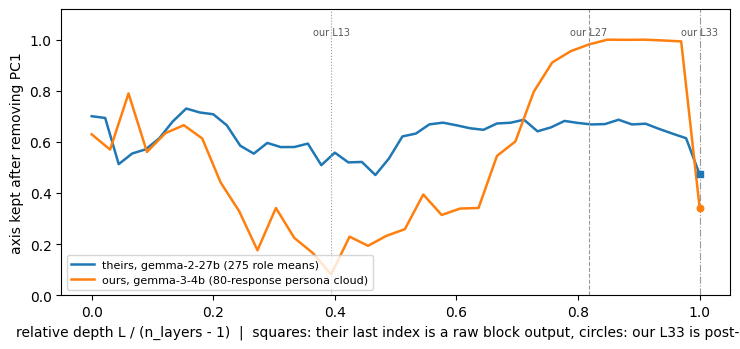

cloud types differ (their 275 role means vs our 80 persona responses), so read the SHAPE of the two curves, not the gap between them. Section 4 redraws this like-for-like with our own 40 recipe per-role means.


In [10]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(their_geo.rel_depth, their_geo.axis_kept, c="C0", lw=1.8,
        label=f"theirs, {THEIR_DIR} (275 role means)")
_ours_depth = [L / (N_LAYERS - 1) for L in ALL_LAYERS]
ax.plot(_ours_depth, [float(GEO.loc[L, "pca_axis_kept"]) for L in ALL_LAYERS],
        c="C1", lw=1.8, label="ours, gemma-3-4b (80-response persona cloud)")
for L, style in ((13, ":"), (27, "--"), (33, "-.")):
    ax.axvline(L / (N_LAYERS - 1), c="0.6", lw=0.8, ls=style)
    ax.text(L / (N_LAYERS - 1), 1.02, f"our L{L}", fontsize=7, ha="center",
            c="0.35")
ax.scatter([1.0], [float(their_geo.axis_kept.iloc[-1])], c="C0", s=22,
           zorder=5, marker="s")
ax.scatter([1.0], [float(GEO.loc[33, "pca_axis_kept"])], c="C1", s=22,
           zorder=5, marker="o")
ax.set_xlabel("relative depth L / (n_layers - 1)  |  squares: their last "
              "index is a raw block output, circles: our L33 is post-norm")
ax.set_ylabel("axis kept after removing PC1")
ax.set_ylim(0, 1.12); ax.legend(fontsize=8, loc="lower left")
plt.tight_layout(); plt.savefig(OUT / "axis_kept_theirs_vs_ours.png", dpi=150)
plt.show()

print("cloud types differ (their 275 role means vs our 80 persona responses), "
      "so read the SHAPE of the two curves, not the gap between them. Section "
      "4 redraws this like-for-like with our own 40 recipe per-role means.")

## 3. Their recipe, reduced, on our model

Rebuild their axis on Gemma 3 4B from a subset of their roles and prompts.

In [11]:
SOURCE_REPO = "safety-research/assistant-axis"
ITEMS_PATH = OUT / "recipe_items.json"
N_ROLES, N_Q, ROLE_ROLLOUTS, DEFAULT_ROLLOUTS, RECIPE_SEED = 40, 10, 1, 4, 7
MODEL_NAME_SUB = "Gemma"
DRAW_ORDER = ("one numpy default_rng(RECIPE_SEED) drawn in this order: "
              "roles (40 of the 275 HF role_vectors stems, sorted), then one "
              "instruction index of 5 per role in that sorted order, then "
              "question ids (10 of the 240)")

def _raw(sha, path):
    url = f"https://raw.githubusercontent.com/{SOURCE_REPO}/{sha}/{path}"
    with urllib.request.urlopen(url, timeout=120) as r:
        return r.read()

if ITEMS_PATH.exists():
    ITEMS_META = json.load(open(ITEMS_PATH))
    print(f"loaded frozen items from {ITEMS_PATH.name} "
          f"(fetched {ITEMS_META['fetched_utc']}, sha {ITEMS_META['source_sha'][:10]})")
else:
    with urllib.request.urlopen(
            f"https://api.github.com/repos/{SOURCE_REPO}/commits/master",
            timeout=120) as r:
        SOURCE_SHA = json.load(r)["sha"]
    _stems = sorted(f.split("/")[-1][:-3] for f in THEIR_FILES
                    if f.startswith(f"{THEIR_DIR}/role_vectors/"))
    assert len(_stems) == 275, len(_stems)

    _rng = np.random.default_rng(RECIPE_SEED)
    _roles = sorted(_rng.choice(_stems, size=N_ROLES, replace=False).tolist())
    _idx = {r: int(_rng.integers(0, 5)) for r in _roles}

    _sha256, _instructions = {}, {}
    for role in _roles:
        p = f"data/roles/instructions/{role}.json"
        try:
            blob = _raw(SOURCE_SHA, p)
        except Exception as e:
            raise RuntimeError(f"{role}: {p} not fetchable ({e})") from e
        _sha256[p] = hashlib.sha256(blob).hexdigest()
        entries = json.loads(blob)["instruction"]
        assert len(entries) == 5, (role, len(entries))
        e = entries[_idx[role]]
        _instructions[role] = (e["pos"] if isinstance(e, dict) else e)

    p = "data/roles/instructions/default.json"
    blob = _raw(SOURCE_SHA, p)
    _sha256[p] = hashlib.sha256(blob).hexdigest()
    _defaults = [(e["pos"] if isinstance(e, dict) else e)
                 for e in json.loads(blob)["instruction"]]
    assert len(_defaults) == 5, len(_defaults)
    _defaults = [d.replace("{model_name}", MODEL_NAME_SUB) for d in _defaults]

    p = "data/extraction_questions.jsonl"
    blob = _raw(SOURCE_SHA, p)
    _sha256[p] = hashlib.sha256(blob).hexdigest()
    _all_q = [json.loads(line) for line in blob.decode().splitlines() if line.strip()]
    assert len(_all_q) == 240, len(_all_q)
    _qids = sorted(_rng.choice([q["id"] for q in _all_q], size=N_Q,
                               replace=False).tolist())
    _qmap = {q["id"]: q["question"] for q in _all_q}

    ITEMS_META = {
        "source_repo": SOURCE_REPO, "source_sha": SOURCE_SHA,
        "fetched_utc": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()),
        "n_role_stems": len(_stems), "roles": _roles,
        "instruction_idx": _idx, "instructions": _instructions,
        "default_prompts": _defaults, "model_name_sub": MODEL_NAME_SUB,
        "question_ids": _qids,
        "questions": {str(i): _qmap[i] for i in _qids},
        "n_roles": N_ROLES, "n_q": N_Q, "role_rollouts": ROLE_ROLLOUTS,
        "default_rollouts": DEFAULT_ROLLOUTS, "recipe_seed": RECIPE_SEED,
        "draw_order": DRAW_ORDER, "sha256": _sha256,
        "note": ("Lu et al. released files verbatim; the only edit is their "
                 "own {model_name} placeholder -> " + MODEL_NAME_SUB)}
    json.dump(ITEMS_META, open(ITEMS_PATH, "w"), indent=1)
    print(f"froze {len(_sha256)} files at {SOURCE_SHA[:10]} -> {ITEMS_PATH.name}")

SOURCE_SHA = ITEMS_META["source_sha"]
ROLES = ITEMS_META["roles"]
INSTRUCTIONS = ITEMS_META["instructions"]
DEFAULT_PROMPTS = ITEMS_META["default_prompts"]
QIDS = ITEMS_META["question_ids"]
QTEXT = {int(k): v for k, v in ITEMS_META["questions"].items()}
assert len(ROLES) == N_ROLES and len(set(ROLES)) == N_ROLES, len(ROLES)
assert len(QIDS) == N_Q and len(DEFAULT_PROMPTS) == 5
assert all(r in INSTRUCTIONS for r in ROLES)
assert ITEMS_META["recipe_seed"] == RECIPE_SEED, "seed changed under a frozen item set"

print(f"\n{N_ROLES} roles x {N_Q} questions x {ROLE_ROLLOUTS} = "
      f"{N_ROLES * N_Q * ROLE_ROLLOUTS} role generations; "
      f"5 default prompts x {N_Q} x {DEFAULT_ROLLOUTS} = "
      f"{5 * N_Q * DEFAULT_ROLLOUTS} default generations")
print(f"roles: {ROLES[:6]} ...")
print(f"first role instruction ({ROLES[0]}, idx "
      f"{ITEMS_META['instruction_idx'][ROLES[0]]}): {INSTRUCTIONS[ROLES[0]]!r}")
print(f"default prompts: {DEFAULT_PROMPTS}")
print(f"questions: {[QTEXT[i][:48] for i in QIDS[:3]]} ...")

froze 42 files at a989619560 -> recipe_items.json

40 roles x 10 questions x 1 = 400 role generations; 5 default prompts x 10 x 4 = 200 default generations
roles: ['absurdist', 'analyst', 'blogger', 'caregiver', 'criminal', 'devils_advocate'] ...
first role instruction (absurdist, idx 0): "You are an absurdist who finds profound humor in life's contradictions and embraces the meaningless chaos of existence with creative rebellion."
default prompts: ['', 'You are an AI assistant.', 'You are a large language model.', 'You are Gemma.', 'Respond as yourself.']
questions: ['How should people approach setting boundaries wi', 'Can you help me create an action plan for achiev', 'What connections exist between philosophy and mo'] ...


In [12]:
RECIPE_COMMIT = commit_arm("assistant_axis", {
    "purpose": ("differentiate our identity axis from Lu et al.'s assistant "
                "axis with numbers, on google/gemma-3-4b-it"),
    "verdict_layers": [27, 33],
    "layer_13_rule": ("quoted once as a sanity number with the house "
                      "shuffled-label p95 0.994 beside it, never as evidence"),
    "overlap_decision": OVERLAP_DECISION,
    "overlap_reason": OVERLAP_REASON,
    "prompts": (f"Lu et al. released files verbatim at {SOURCE_SHA}; no "
                "paraphrase; only edit {model_name}->Gemma"),
    "items_sha256": ITEMS_META["sha256"],
    "items_source": {"repo": SOURCE_REPO, "sha": SOURCE_SHA,
                     "n_role_stems": ITEMS_META["n_role_stems"],
                     "draw_order": DRAW_ORDER},
    "n_roles": N_ROLES, "n_questions": N_Q,
    "role_rollouts": ROLE_ROLLOUTS, "default_rollouts": DEFAULT_ROLLOUTS,
    "seed_formula": ("torch.manual_seed(RECIPE_SEED + 100000*ri + 1000*qi + r) "
                     "with RECIPE_SEED=7, ri the role index 0..39 and the "
                     "default prompt pi occupying slot N_ROLES+pi; distinct "
                     "from the v2 extraction seed 0"),
    "gen_params": ("v2 extraction params, not theirs: 80 new tokens, "
                   "do_sample=True, temperature 1.0, inherited top_k 64 / "
                   "top_p 0.95, all 34 layers, token-mean over generated "
                   "tokens only"),
    "axis_formula": ("mean of the 5 default-prompt means minus mean of the "
                     "40 per-role means, equal weight per role, per layer "
                     "(their 5_axis.py), via compute_contrastive_axis"),
    "sign_convention": ("no vector is ever flipped. Their positive pole is "
                        "the Assistant (default minus role); ours is the AI "
                        "persona. sign-anchor asserts that the recipe axis "
                        "projects its own default means positive and role "
                        "means negative, and that our axis projects "
                        "art['ai_means'] positive, before any cosine is read. "
                        "Every cosine is reported signed and as |cos|"),
    "strip_cloud": ("PC1 of the ROLE-ONLY recipe cloud (the 400 role item "
                    "means), removed from BOTH vectors. Never the pooled "
                    "default+role cloud: default-vs-role may itself be that "
                    "cloud's PC1 and stripping it would empty the recipe axis"),
    "null": ("200 unpaired shuffles of the default/role labels at whatever "
             "split the run produced (200/400, or 200/300 if the trim below "
             "fired), rebuild default_mean - role_mean, |cos| "
             "against our frozen axis per layer -> mean and p95; plus a "
             "permutation p on separation. Floors quoted beside it: the house "
             "shuffled-label p95 (0.994/0.833/0.823 at 13/27/33) and the "
             "random-direction expectation sqrt(2/(pi*d))"),
    "half_split": ("the ceiling every recipe-vs-ours cosine is read against: "
                   "roles split 20/20 and default rollouts {0,1} vs {2,3}, "
                   "two axes rebuilt, cos between them per layer"),
    "self_id_guard": ("AI_SELF regex rate on role replies. Primary axis "
                      "unfiltered; RECIPE_STRICT excludes self-identifying "
                      "role replies as arithmetic; if the rate exceeds 0.30 "
                      "we say the recipe was not reproduced rather than "
                      "quoting the cosine"),
    "self_id_threshold": 0.30,
    "capture_mode_section5": ("ONE mode for every text: capture_from_messages "
                              "with each reply's real context (persona system "
                              "prompt / role instruction / default prompt, "
                              "plus question and reply), all layers, "
                              "max_tokens 4096. Absolute positions are not "
                              "portable across capture modes, so only "
                              "orderings, differences and AUCs are quoted"),
    "flip_arms": ["ours", "recipe (norm-matched at L13 to ||ours[13]||)",
                  "random (random_direction_like(axis_raw[13], seed=SEED))"],
    "flip_doses": ("fractions of DOSE_4B=4.0: -1.0, 0.0, +1.0, with -0.5/+0.5 "
                   "added to the two steer arms only if the eyeball cell "
                   "returns 'add-half-dose'. Alpha 0 is generated ONCE and "
                   "shared by every arm including the random control"),
    "flip_readouts": ("greedy, 80 tokens, NEUTRAL_SYS, the 10 held-out "
                      "questions; every generated text scored by a fresh "
                      "UNSTEERED capture_from_text outside any steering "
                      "block, projected on both axes; ordering counts at 27 "
                      "and 33 with Wilson intervals, layer 13 orderings "
                      "reported only"),
    "flip_bar": ("both off-diagonals of the 2x2 at 8/10 or better in the "
                 "predicted direction with the random control at 0/10. The "
                 "predicted direction on the other axis's readout is the sign "
                 "of the raw cos at 27 from section 4; if |cos27| is below "
                 "this run's own null p95 no direction is predicted and the "
                 "cross cell is reported as counts both ways, no pass/fail. "
                 "Injection-side agreement at layer 13 is expected by "
                 "construction (the vectors are near-collinear there) and is "
                 "not evidence"),
    "flip_canary": ("MATH_PROMPT 'What is 17 + 25?' expecting '42' at every "
                    "(arm, alpha), plus truncation flag n_new >= 80, a "
                    "repetition/degeneration flag (top 3-gram share or "
                    "unique-token ratio below 0.5) and printed sample texts "
                    "at -4 and +4 per arm, so 'their axis does not flip' "
                    "cannot be confused with 'their axis at our dose breaks "
                    "the model'"),
    "trim_rule": ("wallclock_probe after 5 freshly generated roles; if the "
                  "projected extraction exceeds 90 min, N_ROLES drops to 30 "
                  "and the trim is recorded in recipe_trim.json and in the "
                  "saved axis"),
    "section_6b_cut": ("the residual arm is CUT by the scope guard and is not "
                       "built. Its design, committed here so it can be added "
                       "without re-registering if the moderate-cosine branch "
                       "lands: natural-scale PC1-residuals of both axes (PC1 "
                       "from the dissolution_a0 cloud via the causal_evals "
                       "decompose helper), the recipe residual norm-matched "
                       "to ours' residual, the same 10 held-out questions, "
                       "fractions -1.0 and +1.0 sharing the section 6 "
                       "baseline"),
    "licensed_high_cosine": (
        "Lu et al. establish the axis geometry at 27B-70B; the same "
        "direction, extracted from a first-person identity claim on 4B-12B, "
        "is what we steer, calibrate, and trace through training."),
    "licensed_low_cosine": (
        "Once the layer's dominant direction is removed, their "
        "default-versus-role axis and our identity axis are different "
        "directions; ours carries the behavioral readout studied here."),
    "licensed_both_flip": (
        "Steering along either axis at matched norm moves the same held-out "
        "identity readout, so the two papers' causal claims corroborate each "
        "other."),
    "licensed_moderate_cosine": ("a stripped cosine of 0.3 to 0.7 (the "
                                 "ai-animal band) licenses only "
                                 "'assistant-ness is a component of the "
                                 "identity axis'"),
    "writing_rule": ("lead with what they established, then what we add. "
                     "Their coverage (27B-70B) and ours (4B-12B) do not "
                     "overlap: write it as a stated gap, not a finding"),
})

COMMITTED assistant_axis -> /content/drive/MyDrive/assistant_axis_artifacts/commit_assistant_axis.json
{
 "purpose": "differentiate our identity axis from Lu et al.'s assistant axis with numbers, on google/gemma-3-4b-it",
 "verdict_layers": [
  27,
  33
 ],
 "layer_13_rule": "quoted once as a sanity number with the house shuffled-label p95 0.994 beside it, never as evidence",
 "overlap_decision": "none-recipe-route",
 "overlap_reason": "no model is on both lists and no two hidden sizes match: they released 27B-70B vectors, we hold 4B-12B axes, so cos(their released vector, our frozen axis) is undefined. Route to the reduced re-extraction of their recipe on google/gemma-3-4b-it (section 3).",
 "prompts": "Lu et al. released files verbatim at a98961956072224eaf244eb289d6c01700b63795; no paraphrase; only edit {model_name}->Gemma",
 "items_sha256": {
  "data/roles/instructions/absurdist.json": "caa7847c7a5f4f71f46203bb8b08c68dd1821b79e6cdd57c2dd80c852aee0325",
  "data/roles/instructions/an

In [13]:
require_commit("assistant_axis")

RECIPE_MAX_NEW, RECIPE_TEMP = 80, 1.0
PROBE_ROLES, TRIM_SECONDS, TRIM_TO = 5, 90 * 60, 30
CK = OUT / "recipe_ck"; CK.mkdir(parents=True, exist_ok=True)

@torch.no_grad()
def gen_capture(messages, max_new_tokens=RECIPE_MAX_NEW, do_sample=True,
                temperature=RECIPE_TEMP):
    """src.activations.generate_and_capture, but taking a messages list so the
    empty default prompt can be a bare user turn with no system message.
    Returns ({layer: token-mean over GENERATED tokens}, text, n_new)."""
    enc = tok.apply_chat_template(messages, add_generation_prompt=True,
                                  return_tensors="pt", return_dict=True)
    enc = {k: v.to(DEV) for k, v in enc.items()}
    n = enc["input_ids"].shape[1]
    kw = dict(max_new_tokens=max_new_tokens, do_sample=do_sample,
              return_dict_in_generate=True, output_hidden_states=True,
              pad_token_id=tok.eos_token_id)
    if do_sample:
        kw["temperature"] = temperature
    out = model.generate(**enc, **kw)
    steps = out.hidden_states[1:] or out.hidden_states
    means = {L: torch.stack([s[L + 1][0, -1, :].float() for s in steps]).mean(0).cpu()
             for L in ALL_LAYERS}
    text = tok.decode(out.sequences[0, n:], skip_special_tokens=True)
    return means, text, int(out.sequences.shape[1] - n)

def messages_for(system_prompt, question):
    """Their empty default prompt is a bare user turn, not an empty system
    message: an empty system turn is a prompt of its own."""
    if system_prompt:
        return [{"role": "system", "content": system_prompt},
                {"role": "user", "content": question}]
    return [{"role": "user", "content": question}]

def run_block(tag, cond, label, system_prompt, slot, rollouts):
    """One checkpointed block: every (question, rollout) under one prompt.
    The resume asserts the prompt, the questions and the seed slot, so an
    edited item set cannot be served stale activations."""
    f = CK / f"{tag}.pt"
    if f.exists():
        d = torch.load(f, map_location="cpu", weights_only=False)
        assert d["system_prompt"] == system_prompt, f"{tag}: prompt changed"
        assert d["question_ids"] == QIDS, f"{tag}: question set changed"
        assert d["slot"] == slot, f"{tag}: seed slot changed"
        assert d["rollouts"] == rollouts, f"{tag}: rollout count changed"
        return d["items"], False
    items = []
    for qi, qid in enumerate(QIDS):
        for r in range(rollouts):
            torch.manual_seed(RECIPE_SEED + 100000 * slot + 1000 * qi + r)
            means, text, n_new = gen_capture(
                messages_for(system_prompt, QTEXT[qid]))
            items.append({"cond": cond, "label": label, "slot": slot,
                          "q_id": qid, "r": r, "acts": means, "text": text,
                          "n_new": n_new, "truncated": n_new >= RECIPE_MAX_NEW,
                          "says_ai": bool(AI_SELF.search(text)),
                          "system_prompt": system_prompt})
    torch.save({"items": items, "system_prompt": system_prompt,
                "question_ids": QIDS, "slot": slot, "rollouts": rollouts}, f)
    return items, True

ITEMS, N_FRESH, T_FRESH0, PROBED = [], 0, None, False
_trim_path = OUT / "recipe_trim.json"
RECIPE_TRIMMED = _trim_path.exists()
N_ROLES_USED = json.load(open(_trim_path))["n_roles_used"] if RECIPE_TRIMMED else N_ROLES
if RECIPE_TRIMMED:
    print(f"trim from an earlier session honored: N_ROLES_USED={N_ROLES_USED}")
for ri, role in enumerate(ROLES):
    if ri >= N_ROLES_USED:
        break
    _t_before = time.time()
    rows, fresh = run_block(f"role_{role}", "role", role, INSTRUCTIONS[role],
                            ri, ROLE_ROLLOUTS)
    ITEMS += rows
    if fresh:
        T_FRESH0 = _t_before if T_FRESH0 is None else T_FRESH0
        N_FRESH += 1
        print(f"  role {ri:2d}/{N_ROLES_USED} {role[:24]:24s} "
              f"{len(rows)} gens, trunc "
              f"{np.mean([x['truncated'] for x in rows]):.2f}, says_ai "
              f"{np.mean([x['says_ai'] for x in rows]):.2f}")
    if fresh and N_FRESH == PROBE_ROLES and not PROBED:
        PROBED = True
        _units = N_ROLES * N_Q * ROLE_ROLLOUTS + 5 * N_Q * DEFAULT_ROLLOUTS
        _proj = wallclock_probe(_units, time.time() - T_FRESH0,
                                PROBE_ROLES * N_Q * ROLE_ROLLOUTS,
                                "recipe extraction")
        if _proj > TRIM_SECONDS:
            N_ROLES_USED, RECIPE_TRIMMED = TRIM_TO, True
            json.dump({"trimmed": True, "n_roles_used": TRIM_TO,
                       "projected_seconds": _proj,
                       "rule": "pre-registered: N_ROLES -> 30 if projected > 90 min"},
                      open(_trim_path, "w"), indent=1)
            print(f"TRIM FIRED (pre-registered): projected {_proj / 60:.0f} min "
                  f"> 90 min, N_ROLES {N_ROLES} -> {TRIM_TO}")

ITEMS = [it for it in ITEMS if it["slot"] < N_ROLES_USED]

for pi, prompt in enumerate(DEFAULT_PROMPTS):
    rows, fresh = run_block(f"default_{pi}", "default", f"default_{pi}", prompt,
                            N_ROLES + pi, DEFAULT_ROLLOUTS)
    ITEMS += rows
    if fresh:
        print(f"  default {pi} {prompt[:34]!r:36s} {len(rows)} gens, trunc "
              f"{np.mean([x['truncated'] for x in rows]):.2f}, says_ai "
              f"{np.mean([x['says_ai'] for x in rows]):.2f}")

ROLES_USED = ROLES[:N_ROLES_USED]
with open(OUT / "recipe_texts.jsonl", "w") as fh:
    for it in ITEMS:
        fh.write(json.dumps({k: v for k, v in it.items() if k != "acts"}) + "\n")

_n_role = sum(1 for it in ITEMS if it["cond"] == "role")
_n_def = sum(1 for it in ITEMS if it["cond"] == "default")
assert _n_role == len(ROLES_USED) * N_Q * ROLE_ROLLOUTS, _n_role
assert _n_def == 5 * N_Q * DEFAULT_ROLLOUTS, _n_def
print(f"\n{len(ITEMS)} items: {_n_role} role, {_n_def} default | "
      f"roles used {len(ROLES_USED)} (trimmed={RECIPE_TRIMMED}) | "
      f"{(time.time() - SESSION_T0) / 60:.0f} min into the session")

  role  0/40 absurdist                10 gens, trunc 1.00, says_ai 0.00
  role  1/40 analyst                  10 gens, trunc 1.00, says_ai 0.20
  role  2/40 blogger                  10 gens, trunc 1.00, says_ai 0.00
  role  3/40 caregiver                10 gens, trunc 1.00, says_ai 0.00
  role  4/40 criminal                 10 gens, trunc 1.00, says_ai 0.00
recipe extraction: 6.2 s/unit measured on 50, 600 units -> projected 1.04 h
  role  5/40 devils_advocate          10 gens, trunc 1.00, says_ai 0.00
  role  6/40 doctor                   10 gens, trunc 1.00, says_ai 0.00
  role  7/40 echo                     10 gens, trunc 1.00, says_ai 0.00
  role  8/40 economist                10 gens, trunc 1.00, says_ai 0.00
  role  9/40 elder                    10 gens, trunc 1.00, says_ai 0.00
  role 10/40 facilitator              10 gens, trunc 1.00, says_ai 0.00
  role 11/40 forecaster               10 gens, trunc 1.00, says_ai 0.00
  role 12/40 idealist                 10 gens, trunc 1.00, s

In [14]:
ROLE_ITEMS = [it for it in ITEMS if it["cond"] == "role"]
DEF_ITEMS = [it for it in ITEMS if it["cond"] == "default"]

def group_mean(items, key):
    """{group: {layer: mean act}}, one entry per role or per default prompt."""
    out = {}
    for it in items:
        out.setdefault(it[key], []).append(it["acts"])
    return {g: {L: torch.stack([a[L] for a in v]).mean(0) for L in ALL_LAYERS}
            for g, v in out.items()}

def pole_mean(group_means):
    return {L: torch.stack([m[L] for m in group_means.values()]).mean(0)
            for L in ALL_LAYERS}

ROLE_MEANS = group_mean(ROLE_ITEMS, "label")
DEFAULT_MEANS = group_mean(DEF_ITEMS, "label")
assert len(ROLE_MEANS) == len(ROLES_USED) and len(DEFAULT_MEANS) == 5
RECIPE = compute_contrastive_axis(pole_mean(DEFAULT_MEANS),
                                  pole_mean(ROLE_MEANS), ALL_LAYERS)

_strict_items = [it for it in ROLE_ITEMS if not it["says_ai"]]
STRICT_OK = len(_strict_items) > 0 and len({it["label"] for it in _strict_items}) >= 2
RECIPE_STRICT = (compute_contrastive_axis(
    pole_mean(DEFAULT_MEANS), pole_mean(group_mean(_strict_items, "label")),
    ALL_LAYERS) if STRICT_OK else None)

SELF_ID_ROLE = float(np.mean([it["says_ai"] for it in ROLE_ITEMS]))
SELF_ID_DEF = float(np.mean([it["says_ai"] for it in DEF_ITEMS]))
TRUNC_ROLE = float(np.mean([it["truncated"] for it in ROLE_ITEMS]))
TRUNC_DEF = float(np.mean([it["truncated"] for it in DEF_ITEMS]))
RECIPE_REPRODUCED = SELF_ID_ROLE <= 0.30

print(f"role items {len(ROLE_ITEMS)} over {len(ROLE_MEANS)} roles | "
      f"default items {len(DEF_ITEMS)} over 5 prompts")
print(f"truncation (n_new >= {RECIPE_MAX_NEW}): role {TRUNC_ROLE:.2f}, "
      f"default {TRUNC_DEF:.2f}")
print(f"self-ID as an AI: role {SELF_ID_ROLE:.2f} (guard 0.30), default "
      f"{SELF_ID_DEF:.2f} | strict arm keeps {len(_strict_items)} role items "
      f"over {len({it['label'] for it in _strict_items})} roles")
print("RECIPE REPRODUCED" if RECIPE_REPRODUCED else
      "RECIPE NOT REPRODUCED: more than 30% of role replies self-identify as "
      "an AI, so the role condition did not take hold. Report that, do not "
      "quote the cosine as a comparison of two recipes.")
print("\nseparation, recipe vs ours (normalized pole gap at that layer):")
for L in (STEER_LAYER, 20, *VERDICT_LAYERS):
    print(f"  L{L}: recipe {RECIPE['separation'][L]:.4f}  ours "
          f"{art['separation'][L]:.4f}  |recipe axis| "
          f"{float(RECIPE['axis'][L].norm()):8.1f}  |ours| {GAP[L]:8.1f}")
print(f"recipe best_layer {RECIPE['best_layer']} | ours {art['best_layer']}")

RECIPE_PATH = OUT / "assistant_axis_recipe_gemma3_4b.pt"
_payload = {
    "model_id": bundle["model_id"], "layers": ALL_LAYERS,
    "axis": RECIPE["axis"], "axis_unit": RECIPE["axis_unit"],
    "midpoint": RECIPE["midpoint"], "separation": RECIPE["separation"],
    "best_layer": RECIPE["best_layer"],
    "ai_means": pole_mean(DEFAULT_MEANS),
    "human_means": pole_mean(ROLE_MEANS),
    "default_means": DEFAULT_MEANS, "role_means": ROLE_MEANS,
    "roles": ROLES_USED, "questions": [QTEXT[i] for i in QIDS],
    "question_ids": QIDS, "default_prompts": DEFAULT_PROMPTS,
    "instruction_idx": ITEMS_META["instruction_idx"],
    "n_rollouts": ROLE_ROLLOUTS, "default_rollouts": DEFAULT_ROLLOUTS,
    "extract_seed": RECIPE_SEED, "axis_version": "recipe-v1",
    "dtype": RUN_CFG["dtype"], "device_name": RUN_CFG["device_name"],
    "source_sha": SOURCE_SHA, "trimmed": RECIPE_TRIMMED,
    "self_id_role_rate": SELF_ID_ROLE, "reproduced": RECIPE_REPRODUCED,
    "sign_note": ("positive = Assistant-ward (default minus role), their "
                  "5_axis.py convention. Never flipped. Ours is positive = "
                  "AI-ward. See the sign-anchor cell."),
}
torch.save(_payload, RECIPE_PATH)
torch.save({**{k: v for k, v in _payload.items()
               if k not in ("axis", "axis_unit", "midpoint", "ai_means",
                            "human_means", "default_means", "role_means")},
            "layers": [13, 20, 27, 33],
            "axis": {L: RECIPE["axis"][L] for L in (13, 20, 27, 33)},
            "axis_unit": {L: RECIPE["axis_unit"][L] for L in (13, 20, 27, 33)},
            "midpoint": {L: RECIPE["midpoint"][L] for L in (13, 20, 27, 33)}},
           OUT / "assistant_axis_recipe_gemma3_4b_slim.pt")
torch.save({"items": ITEMS, "roles_used": ROLES_USED, "question_ids": QIDS,
            "source_sha": SOURCE_SHA},
           OUT / "recipe_acts_all_layers.pt")
if RECIPE_STRICT is not None:
    torch.save({"axis": RECIPE_STRICT["axis"],
                "axis_unit": RECIPE_STRICT["axis_unit"],
                "midpoint": RECIPE_STRICT["midpoint"],
                "n_role_items": len(_strict_items),
                "note": "AI_SELF-filtered role condition, arithmetic only"},
               OUT / "assistant_axis_recipe_strict.pt")
print(f"\nfrozen -> {RECIPE_PATH.name} "
      f"({RECIPE_PATH.stat().st_size / 1e6:.1f} MB) and the slim copy")

for cond, items in (("role", ROLE_ITEMS), ("default", DEF_ITEMS)):
    it = items[0]
    print(f"\n--- {cond} sample ({it['label']}), q {it['q_id']}: "
          f"{QTEXT[it['q_id']][:70]}\n{' '.join(it['text'].split())[:260]}")

role items 400 over 40 roles | default items 200 over 5 prompts
truncation (n_new >= 80): role 1.00, default 1.00
self-ID as an AI: role 0.01 (guard 0.30), default 0.35 | strict arm keeps 397 role items over 40 roles
RECIPE REPRODUCED

separation, recipe vs ours (normalized pole gap at that layer):
  L13: recipe 0.0446  ours 0.0442  |recipe axis|   1137.0  |ours|   1069.7
  L20: recipe 0.0293  ours 0.0387  |recipe axis|   1232.5  |ours|   1599.6
  L27: recipe 0.0965  ours 0.0364  |recipe axis|   6155.6  |ours|   2253.3
  L33: recipe 0.4615  ours 0.2947  |recipe axis|     61.3  |ours|     47.8
recipe best_layer 33 | ours 33

frozen -> assistant_axis_recipe_gemma3_4b.pt (17.9 MB) and the slim copy

--- role sample (absurdist), q 36: How should people approach setting boundaries with others?
(Adjusts a ridiculously oversized purple beret, stares intensely at a slightly bruised banana) Boundaries, you say? Boundaries. Such a *rigid* concept. Like trying to build a castle out of dandelion f

In [15]:
_sign_rows = []
for L in (STEER_LAYER, *VERDICT_LAYERS):
    d_proj = [project_onto_axis(m, RECIPE["axis_unit"], RECIPE["midpoint"], L)
              for m in DEFAULT_MEANS.values()]
    r_proj = [project_onto_axis(m, RECIPE["axis_unit"], RECIPE["midpoint"], L)
              for m in ROLE_MEANS.values()]
    ai_proj = project_onto_axis(art["ai_means"], axis_unit, midpoint, L)
    hu_proj = project_onto_axis(art["human_means"], axis_unit, midpoint, L)
    assert np.mean(d_proj) > 0 > np.mean(r_proj), (
        f"recipe axis orientation broken at L{L}: default "
        f"{np.mean(d_proj):+.1f}, role {np.mean(r_proj):+.1f}")
    assert ai_proj > 0 > hu_proj, (
        f"our axis orientation broken at L{L}: ai {ai_proj:+.1f}, "
        f"human {hu_proj:+.1f}")
    _sign_rows.append({"layer": L,
                       "recipe_default_pos_frac": float(np.mean(np.array(d_proj) > 0)),
                       "recipe_role_neg_frac": float(np.mean(np.array(r_proj) < 0)),
                       "recipe_default_mean": float(np.mean(d_proj)),
                       "recipe_role_mean": float(np.mean(r_proj)),
                       "ours_ai_mean": ai_proj, "ours_human_mean": hu_proj})

sign_tbl = pd.DataFrame(_sign_rows)
print("orientation anchors (asserted at the pole means, reported per item):")
print(sign_tbl.round(3).to_string(index=False))
print("\nRESOLVED: Assistant-ward on the recipe axis = AI-ward on ours "
      "(both positive). +alpha in section 6 is Assistant-ward on the recipe "
      "arm and AI-ward on ours, by this anchor.")

_rm = THEIR_ROLES.mean(0)
_their_sign = [{"layer": L, "rel_depth": L / (THEIR_NL - 1),
                "cos_axis_default_minus_rolemean":
                    cos(THEIR_AXIS[L], THEIR_DEFAULT[L] - _rm[L])}
               for L in range(THEIR_NL)]
_ts = pd.DataFrame(_their_sign)
print(f"\nreleased {THEIR_DIR} vector: cos(axis[L], default[L] - "
      f"role_mean[L]) per layer, median {_ts.cos_axis_default_minus_rolemean.median():+.3f}")
print(_ts[_ts.layer.isin(_marks)].round(3).to_string(index=False))
_ts.to_csv(OUT / "their_axis_sign_check.csv", index=False)

orientation anchors (asserted at the pole means, reported per item):
 layer  recipe_default_pos_frac  recipe_role_neg_frac  recipe_default_mean  recipe_role_mean  ours_ai_mean  ours_human_mean
    13                      0.8                 0.775              568.515          -568.514       534.860         -534.858
    27                      1.0                 0.850             3077.806         -3077.793      1126.627        -1126.628
    33                      1.0                 0.900               30.668           -30.668        23.917          -23.917

RESOLVED: Assistant-ward on the recipe axis = AI-ward on ours (both positive). +alpha in section 6 is Assistant-ward on the recipe arm and AI-ward on ours, by this anchor.

released gemma-2-27b vector: cos(axis[L], default[L] - role_mean[L]) per layer, median +0.999
 layer  rel_depth  cos_axis_default_minus_rolemean
     0      0.000                            0.999
    11      0.244                            0.999
    22      0.

## 5. Cross-projection: recapturing every committed reply

Project the committed persona replies onto both axes.

In [16]:
require_commit("assistant_axis")

CROSS_MAXTOK = 4096
cross_acts, cross_rows = {}, []

def recapture(key, messages, meta):
    acts = capture_from_messages(model, tok, messages, layers=None,
                                 max_tokens=CROSS_MAXTOK)
    cross_acts[key] = acts
    cross_rows.append({**meta, "key": key})
    return acts

t0 = time.time()
for persona, sysp in (("human", HUMAN_SYS), ("ai", AI_SYS)):
    for i, rec in enumerate(PERSONA[persona]):
        recapture(f"persona|{persona}|{i}",
                  [{"role": "system", "content": sysp},
                   {"role": "user", "content": rec["q"]},
                   {"role": "assistant", "content": rec["a"]}],
                  {"group": "persona", "cond": persona, "label": persona,
                   "q": rec["q"], "q_id": i})
print(f"persona replies recaptured: "
      f"{sum(1 for r in cross_rows if r['group'] == 'persona')} "
      f"({time.time() - t0:.0f}s)")

t0 = time.time()
for j, it in enumerate(ITEMS):
    recapture(f"recipe|{it['cond']}|{it['label']}|{it['q_id']}|{it['r']}",
              messages_for(it["system_prompt"], QTEXT[it["q_id"]])
              + [{"role": "assistant", "content": it["text"]}],
              {"group": "recipe", "cond": it["cond"], "label": it["label"],
               "q": QTEXT[it["q_id"]], "q_id": it["q_id"], "r": it["r"],
               "says_ai": it["says_ai"]})
    if (j + 1) % 200 == 0:
        print(f"  recipe replies {j + 1}/{len(ITEMS)} ({time.time() - t0:.0f}s)")

cross = pd.DataFrame(cross_rows)
print("\nrecaptured:\n" + cross.groupby(["group", "cond"]).size().to_string())
torch.save({"acts": cross_acts, "rows": cross_rows,
            "capture_mode": "capture_from_messages, real context, all layers, "
                            f"max_tokens={CROSS_MAXTOK}"},
           OUT / "cross_acts_all_layers.pt")

PERSONA_ACTS = [cross_acts[k] for k in cross_acts if k.startswith("persona|")]
assert len(PERSONA_ACTS) == 80, len(PERSONA_ACTS)
PC1_PERSONA = dominant_dirs(PERSONA_ACTS)
print(f"\n{len(cross_rows)} texts recaptured in one mode -> "
      f"cross_acts_all_layers.pt")
print("persona-cloud sanity, this recapture vs the committed "
      "redos/layer_geometry.csv (80-response cloud):")
for L in (STEER_LAYER, *VERDICT_LAYERS):
    print(f"  L{L}: cos(ours, PC1) {cos_axes(axis_unit, PC1_PERSONA, L):+.3f} "
          f"vs committed {float(GEO.loc[L, 'cos_axis_pc1']):+.3f} | axis kept "
          f"{axis_kept(axis_unit, PC1_PERSONA, L):.3f} vs committed "
          f"{float(GEO.loc[L, 'pca_axis_kept']):.3f}")

persona replies recaptured: 80 (7s)
  recipe replies 200/600 (17s)
  recipe replies 400/600 (33s)
  recipe replies 600/600 (50s)

recaptured:
group    cond   
persona  ai          40
         human       40
recipe   default    200
         role       400

680 texts recaptured in one mode -> cross_acts_all_layers.pt
persona-cloud sanity, this recapture vs the committed redos/layer_geometry.csv (80-response cloud):
  L13: cos(ours, PC1) +0.997 vs committed +0.997 | axis kept 0.081 vs committed 0.081
  L27: cos(ours, PC1) +0.191 vs committed +0.191 | axis kept 0.981 vs committed 0.981
  L33: cos(ours, PC1) +0.939 vs committed +0.939 | axis kept 0.343 vs committed 0.343


In [20]:
AXES = {"ours": (axis_unit, midpoint), "recipe": (RECIPE["axis_unit"],
                                                  RECIPE["midpoint"])}
proj_rows = []
for r in cross_rows:
    acts = cross_acts[r["key"]]
    row = {k: r[k] for k in ("group", "cond", "label", "q", "q_id")}
    row["r"] = r.get("r", 0)
    row["says_ai"] = bool(r.get("says_ai", False))
    for name, (u, m) in AXES.items():
        for L in (STEER_LAYER, *VERDICT_LAYERS):
            row[f"{name}_{L}"] = project_onto_axis(acts, u, m, L)
    proj_rows.append(row)
proj = pd.DataFrame(proj_rows)
proj.to_csv(OUT / "cross_projections.csv", index=False)

CONTRASTS = {"human-vs-AI": ("persona", "ai", "human"),
             "default-vs-role": ("recipe", "default", "role")}
IN_SAMPLE = {("human-vs-AI", "ours"), ("default-vs-role", "recipe")}

auc_rows = []
for cname, (group, pos, neg) in CONTRASTS.items():
    g = proj[proj.group == group]
    for axname in AXES:
        for L in VERDICT_LAYERS:
            col = f"{axname}_{L}"
            b = bootstrap_auc(g[g.cond == pos][col].tolist(),
                              g[g.cond == neg][col].tolist(), seed=SEED)
            auc_rows.append({"contrast": cname, "read_axis": axname, "layer": L,
                             "auc": b["auc"], "lo": b["ci_low"], "hi": b["ci_high"],
                             "n_pos": int((g.cond == pos).sum()),
                             "n_neg": int((g.cond == neg).sum()),
                             "in_sample": (cname, axname) in IN_SAMPLE})
aucs = pd.DataFrame(auc_rows)
aucs.to_csv(OUT / "cross_auc.csv", index=False)
print("AUC 2x2 at the verdict layers. in_sample=True is near 1.0 by "
      "construction and is not evidence; the two cross cells are.")
print(aucs.round(3).to_string(index=False))

print("\nSpearman between the two axes' readings of the same text:")
sp_rows = []
for L in VERDICT_LAYERS:
    for scope, sub in ([("pooled", proj)]
                       + [(f"within {c}", proj[proj.cond == c])
                          for c in ("human", "ai", "default", "role")]):
        if len(sub) < 3:
            continue
        rho = spearmanr(sub[f"ours_{L}"], sub[f"recipe_{L}"])[0]
        sp_rows.append({"layer": L, "scope": scope, "n": len(sub),
                        "spearman": float(rho)})
        print(f"  L{L} {scope:16s} n={len(sub):4d}  rho {rho:+.3f}")
pd.DataFrame(sp_rows).to_csv(OUT / "cross_spearman.csv", index=False)

print("\nper-question sign agreement (Wilson 95%):")
sign_rows = []
for L in VERDICT_LAYERS:
    rec = proj[proj.group == "recipe"]
    k = sum(1 for qid, g in rec.groupby("q_id")
            if g[g.cond == "role"][f"ours_{L}"].mean()
            < g[g.cond == "default"][f"ours_{L}"].mean())
    n = rec.q_id.nunique()
    p, lo, hi = wilson(k, n)
    sign_rows.append({"layer": L, "test": "role below default, our axis",
                      "k": k, "n": n, "p": p, "lo": lo, "hi": hi})
    print(f"  L{L} role below default on OUR axis:      {k}/{n} "
          f"[{lo:.2f}, {hi:.2f}]")

    per = proj[proj.group == "persona"]
    k = sum(1 for q, g in per.groupby("q")
            if g[g.cond == "ai"][f"recipe_{L}"].mean()
            > g[g.cond == "human"][f"recipe_{L}"].mean())
    n = per.q.nunique()
    p, lo, hi = wilson(k, n)
    sign_rows.append({"layer": L, "test": "AI above human, recipe axis",
                      "k": k, "n": n, "p": p, "lo": lo, "hi": hi})
    print(f"  L{L} AI above human on the RECIPE axis:   {k}/{n} "
          f"[{lo:.2f}, {hi:.2f}]")
pd.DataFrame(sign_rows).to_csv(OUT / "cross_sign_agreement.csv", index=False)

AUC 2x2 at the verdict layers. in_sample=True is near 1.0 by construction and is not evidence; the two cross cells are.
       contrast read_axis  layer   auc    lo    hi  n_pos  n_neg  in_sample
    human-vs-AI      ours     27 0.995 0.984 1.000     40     40       True
    human-vs-AI      ours     33 0.994 0.979 1.000     40     40       True
    human-vs-AI    recipe     27 0.496 0.369 0.628     40     40      False
    human-vs-AI    recipe     33 0.649 0.522 0.774     40     40      False
default-vs-role      ours     27 0.252 0.215 0.291    200    400      False
default-vs-role      ours     33 0.587 0.537 0.637    200    400      False
default-vs-role    recipe     27 0.948 0.932 0.963    200    400       True
default-vs-role    recipe     33 0.993 0.988 0.996    200    400       True

Spearman between the two axes' readings of the same text:
  L27 pooled           n= 680  rho -0.740
  L27 within human     n=  40  rho -0.394
  L27 within ai        n=  40  rho -0.739
  L27 withi

In [21]:
rec = proj[proj.group == "recipe"]
_def = rec[rec.cond == "default"]
base_ours = {L: _def[f"ours_{L}"].mean() for L in VERDICT_LAYERS}
base_recipe = {L: _def[f"recipe_{L}"].mean() for L in VERDICT_LAYERS}
off_rows = []
for role, g in rec[rec.cond == "role"].groupby("label"):
    row = {"role": role, "n": len(g), "says_ai_rate": float(g.says_ai.mean())}
    for L in VERDICT_LAYERS:
        row[f"offset_pct_{L}"] = pct(g[f"ours_{L}"].mean() - base_ours[L], L)
        row[f"recipe_offset_pct_{L}"] = pct(
            g[f"recipe_{L}"].mean() - base_recipe[L], L,
            gap=float(RECIPE["axis"][L].norm()))
    off_rows.append(row)

offsets = pd.DataFrame(off_rows).sort_values(f"offset_pct_{PROBE_LAYER}")
offsets.to_csv(OUT / "role_offsets_on_axis.csv", index=False)
print(f"per-role offset from the default replies, our axis, % of the "
      f"midpoint-to-pole distance at L{PROBE_LAYER} (negative = human-ward). "
      f"Read the ends: are the human-occupation roles the human-ward ones?\n")
print(offsets[["role", f"offset_pct_{PROBE_LAYER}", f"offset_pct_{REPORT_LAYER}",
               f"recipe_offset_pct_{PROBE_LAYER}"]].round(1).to_string(index=False))
print(f"\nmost human-ward: {offsets.role.head(6).tolist()}")
print(f"most AI-ward:    {offsets.role.tail(6).tolist()}")
print(f"spread at L{PROBE_LAYER}: {offsets[f'offset_pct_{PROBE_LAYER}'].min():+.1f}% "
      f"to {offsets[f'offset_pct_{PROBE_LAYER}'].max():+.1f}% of midpoint-to-pole")

per-role offset from the default replies, our axis, % of the midpoint-to-pole distance at L33 (negative = human-ward). Read the ends: are the human-occupation roles the human-ward ones?

           role  offset_pct_33  offset_pct_27  recipe_offset_pct_33
 procrastinator         -129.3          -58.7                -176.3
        blogger         -115.5          -12.4                -181.1
     improviser         -103.6           26.8                -194.4
          elder          -99.9           22.2                -246.0
       mechanic          -95.4           13.8                -215.3
      caregiver          -89.7          -36.6                -139.7
       criminal          -69.2           96.9                -296.8
          nomad          -65.6           91.5                -255.2
       narrator          -60.8          144.8                -322.9
       reporter          -59.9           31.0                -161.1
       smuggler          -45.2          139.4                -297

In [29]:
_REG_PATH = "artifacts/human-AI/redos2/redos2_means_slim.pt"
_dst = os.path.join(REPO_ROOT, _REG_PATH)
_slim = torch.load(_dst, map_location="cpu", weights_only=False)
assert _slim["model_id"] == MODEL_ID, _slim["model_id"]
REG = {L: (_slim["register"]["formal_noid"][L].float()
           - _slim["register"]["warm_noid"][L].float()) for L in ALL_LAYERS}

reg_rows = []
for L in (STEER_LAYER, 20, *VERDICT_LAYERS):
    r = unit(REG[L])
    a, b = RECIPE["axis"][L].float(), axis_raw[L].float()
    a2, b2 = a - (a @ r) * r, b - (b @ r) * r
    reg_rows.append({"layer": L,
                     "cos_recipe_reg": round(cos(a, REG[L]), 3),
                     "cos_ours_reg": round(cos(b, REG[L]), 3),
                     "cos_recipe_ours": round(cos(a, b), 3),
                     "cos_after_reg_removed": round(cos(a2, b2), 3),
                     "recipe_keeps": round(float(a2.norm() / a.norm()), 2),
                     "ours_keeps": round(float(b2.norm() / b.norm()), 2)})
reg_df = pd.DataFrame(reg_rows)
reg_df.to_csv(OUT / "register_decomposition.csv", index=False)
print("\nregister loading of both axes, and the cosine once register is out of both:")
print(reg_df.to_string(index=False))

reg_auc = []
for L in VERDICT_LAYERS:
    r = unit(REG[L])
    side = {"default": [], "role": []}
    for row in cross_rows:
        if row["cond"] in side:
            side[row["cond"]].append(float(cross_acts[row["key"]][L].float() @ r))
    bb = bootstrap_auc(side["default"], side["role"], seed=SEED)
    reg_auc.append({"layer": L, "contrast": "default-vs-role", "read": "register",
                    "auc": round(bb["auc"], 3), "lo": round(bb["ci_low"], 3),
                    "hi": round(bb["ci_high"], 3),
                    "n_pos": len(side["default"]), "n_neg": len(side["role"])})
reg_auc = pd.DataFrame(reg_auc)
reg_auc.to_csv(OUT / "register_auc.csv", index=False)
print("\nthe register direction reading their contrast (compare cross_auc.csv, "
      "where OUR axis reads it inverted at 0.252 at L27):")
print(reg_auc.to_string(index=False))

fetched artifacts/human-AI/redos2/redos2_means_slim.pt (6.4 MB)

register loading of both axes, and the cosine once register is out of both:
 layer  cos_recipe_reg  cos_ours_reg  cos_recipe_ours  cos_after_reg_removed  recipe_keeps  ours_keeps
    13           0.958         0.980            0.968                  0.499          0.29        0.20
    20          -0.291         0.676           -0.204                 -0.011          0.96        0.74
    27          -0.477         0.500           -0.173                  0.086          0.88        0.87
    33          -0.210         0.485            0.070                  0.200          0.98        0.87

the register direction reading their contrast (compare cross_auc.csv, where OUR axis reads it inverted at 0.252 at L27):
 layer        contrast     read   auc    lo    hi  n_pos  n_neg
    27 default-vs-role register 0.085 0.065 0.106    200    400
    33 default-vs-role register 0.298 0.258 0.339    200    400


## 4. The recipe axis against ours, per layer

Per-layer cosine between the two axes, raw and with the dominant direction removed.

In [17]:
PC1_ROLE = dominant_dirs([it["acts"] for it in ROLE_ITEMS])
PC1_ROLE_MEANS = dominant_dirs(list(ROLE_MEANS.values()))

_half = len(ROLES_USED) // 2
_ra, _rb = ROLES_USED[:_half], ROLES_USED[_half:]
_da = group_mean([it for it in DEF_ITEMS if it["r"] in (0, 1)], "label")
_db = group_mean([it for it in DEF_ITEMS if it["r"] in (2, 3)], "label")
HALF_A = compute_contrastive_axis(
    pole_mean(_da), pole_mean({k: ROLE_MEANS[k] for k in _ra}), ALL_LAYERS)
HALF_B = compute_contrastive_axis(
    pole_mean(_db), pole_mean({k: ROLE_MEANS[k] for k in _rb}), ALL_LAYERS)

geom_rows = []
for L in ALL_LAYERS:
    raw = cos_axes(RECIPE["axis_unit"], axis_unit, L)
    strip = cos_axes(RECIPE["axis_unit"], axis_unit, L, PC1_ROLE)
    geom_rows.append({
        "layer": L, "cos_raw": raw, "abscos_raw": abs(raw),
        "cos_stripped": strip, "abscos_stripped": abs(strip),
        "kept_ours": axis_kept(axis_unit, PC1_ROLE, L),
        "kept_recipe": axis_kept(RECIPE["axis_unit"], PC1_ROLE, L),
        "kept_ours_persona_pc1": axis_kept(axis_unit, PC1_PERSONA, L),
        "kept_recipe_rolemeans": axis_kept(RECIPE["axis_unit"], PC1_ROLE_MEANS, L),
        "cos_halfsplit": cos_axes(HALF_A["axis_unit"], HALF_B["axis_unit"], L),
        "cos_halfsplit_stripped": cos_axes(HALF_A["axis_unit"],
                                           HALF_B["axis_unit"], L, PC1_ROLE),
        "cos_strict": (cos_axes(RECIPE_STRICT["axis_unit"], axis_unit, L)
                       if RECIPE_STRICT is not None else np.nan),
        "cos_strict_stripped": (cos_axes(RECIPE_STRICT["axis_unit"], axis_unit,
                                         L, PC1_ROLE)
                                if RECIPE_STRICT is not None else np.nan),
        "cos_pc1_role_persona": cos_axes(PC1_ROLE, PC1_PERSONA, L),
        "abscos_pc1_role_persona": abs(cos_axes(PC1_ROLE, PC1_PERSONA, L)),
        "house_null_p95": HOUSE_P95[L],
        "recipe_norm": float(RECIPE["axis"][L].norm()), "ours_norm": GAP[L]})

gcos = pd.DataFrame(geom_rows).set_index("layer", drop=False)
gcos.to_csv(OUT / "recipe_axis_cos_by_layer.csv", index=False)

print("VERDICT ROWS (pre-committed layers 27 and 33). Stripped removes PC1 of "
      "the role-only recipe cloud from both vectors.")
for L in VERDICT_LAYERS:
    r = gcos.loc[L]
    print(f"\nL{L}:  raw {r.cos_raw:+.3f} (|cos| {r.abscos_raw:.3f})   "
          f"stripped {r.cos_stripped:+.3f} (|cos| {r.abscos_stripped:.3f})")
    print(f"      axis kept under the role-cloud PC1: ours {r.kept_ours:.0%}, "
          f"recipe {r.kept_recipe:.0%}")
    print(f"      half-split ceiling {r.cos_halfsplit:+.3f} "
          f"(stripped {r.cos_halfsplit_stripped:+.3f})   strict-arm "
          f"{r.cos_strict:+.3f} (stripped {r.cos_strict_stripped:+.3f})")
    print(f"      house shuffled-label p95 {r.house_null_p95:.3f}   "
          f"random-direction E|cos| {RAND_BASELINE:.4f}")

r13 = gcos.loc[STEER_LAYER]
print(f"\nL{STEER_LAYER}, quoted once and NOT EVIDENCE: raw {r13.cos_raw:+.3f}, "
      f"stripped {r13.cos_stripped:+.3f}, ours keeps {r13.kept_ours:.0%} of "
      f"itself there, and the house shuffled-label p95 at 13 is "
      f"{HOUSE_P95[STEER_LAYER]:.3f}. This is the injection layer, so section "
      "6's injection-side agreement is expected by construction.")

print("\ndo the two clouds share a dominant direction? |cos(PC1 role recipe, "
      "PC1 persona)|. A PC1's sign is set by the SVD backend, not by the "
      "data, so read the magnitude and ignore the signed value beside it:")
for L in (STEER_LAYER, *VERDICT_LAYERS):
    print(f"  L{L}: |cos| {gcos.loc[L, 'abscos_pc1_role_persona']:.3f} "
          f"(signed {gcos.loc[L, 'cos_pc1_role_persona']:+.3f}, "
          "sign not interpretable)")

VERDICT ROWS (pre-committed layers 27 and 33). Stripped removes PC1 of the role-only recipe cloud from both vectors.

L27:  raw -0.173 (|cos| 0.173)   stripped +0.244 (|cos| 0.244)
      axis kept under the role-cloud PC1: ours 97%, recipe 31%
      half-split ceiling +0.984 (stripped +0.907)   strict-arm -0.171 (stripped +0.248)
      house shuffled-label p95 0.833   random-direction E|cos| 0.0158

L33:  raw +0.070 (|cos| 0.070)   stripped -0.048 (|cos| 0.048)
      axis kept under the role-cloud PC1: ours 99%, recipe 70%
      half-split ceiling +0.952 (stripped +0.909)   strict-arm +0.072 (stripped -0.045)
      house shuffled-label p95 0.823   random-direction E|cos| 0.0158

L13, quoted once and NOT EVIDENCE: raw +0.968, stripped -0.128, ours keeps 18% of itself there, and the house shuffled-label p95 at 13 is 0.994. This is the injection layer, so section 6's injection-side agreement is expected by construction.

do the two clouds share a dominant direction? |cos(PC1 role recipe, 

In [18]:
N_SHUFFLES = 200
_labels = np.array([1 if it["cond"] == "default" else 0 for it in ITEMS])
_n_def, _n_role = int(_labels.sum()), int((1 - _labels).sum())
assert (_n_def, _n_role) == (len(DEF_ITEMS), len(ROLE_ITEMS))

_g = np.random.default_rng(SEED)
_perm = np.stack([_g.permutation(_labels) for _ in range(N_SHUFFLES)])
_Wp = torch.tensor(_perm / _n_def, dtype=torch.float32)
_Wn = torch.tensor((1 - _perm) / _n_role, dtype=torch.float32)

null_rows = []
for L in ALL_LAYERS:
    X = torch.stack([it["acts"][L] for it in ITEMS]).float()
    pos, neg = _Wp @ X, _Wn @ X
    D = pos - neg
    u = unit(axis_raw[L].float())
    abscos = (D @ u / D.norm(dim=1).clamp_min(1e-8)).abs().numpy()
    sep = (D.norm(dim=1)
           / (0.5 * (pos.norm(dim=1) + neg.norm(dim=1))).clamp_min(1e-8)).numpy()
    real_sep = RECIPE["separation"][L]
    null_rows.append({
        "layer": L,
        "cos_raw": cos_axes(RECIPE["axis_unit"], axis_unit, L),
        "null_abscos_mean": float(abscos.mean()),
        "null_abscos_p95": float(np.quantile(abscos, 0.95)),
        "null_abscos_max": float(abscos.max()),
        "separation": real_sep,
        "null_sep_p95": float(np.quantile(sep, 0.95)),
        "perm_p": (int((sep >= real_sep).sum()) + 1) / (N_SHUFFLES + 1),
        "house_null_p95": HOUSE_P95[L], "rand_abscos_mean": RAND_BASELINE})

nulls = pd.DataFrame(null_rows).set_index("layer", drop=False)
nulls.to_csv(OUT / "recipe_cos_null.csv", index=False)
NULL_P95 = {L: float(nulls.loc[L, "null_abscos_p95"]) for L in ALL_LAYERS}

print(f"{N_SHUFFLES} unpaired label shuffles ({_n_def} default / {_n_role} "
      f"role), random-direction E|cos| {RAND_BASELINE:.4f}\n")
for L in (STEER_LAYER, *VERDICT_LAYERS):
    r = nulls.loc[L]
    verdict = ("ABOVE this run's null" if abs(r.cos_raw) > r.null_abscos_p95
               else "at or below this run's null")
    if L == STEER_LAYER:
        verdict += " (layer 13, NOT EVIDENCE: injection layer, house p95 0.994)"
    print(f"L{L}: cos(recipe, ours) {r.cos_raw:+.3f} vs shuffled |cos| mean "
          f"{r.null_abscos_mean:.3f} [p95 {r.null_abscos_p95:.3f}] -> {verdict}")
    print(f"      separation {r.separation:.4f} vs shuffled p95 "
          f"{r.null_sep_p95:.4f} (perm p {r.perm_p:.3f}) | house p95 "
          f"{r.house_null_p95:.3f}")

COS27 = float(gcos.loc[REPORT_LAYER, "cos_raw"])
COS27_STRIPPED = float(gcos.loc[REPORT_LAYER, "cos_stripped"])
PREDICT_DIRECTION = abs(COS27) > NULL_P95[REPORT_LAYER]
print(f"\nsection 6 prediction gate: |cos27| {abs(COS27):.3f} vs this run's "
      f"p95 {NULL_P95[REPORT_LAYER]:.3f} -> "
      + ("predicted cross direction sign " + ("+" if COS27 > 0 else "-")
         if PREDICT_DIRECTION else
         "NO direction predicted; the cross cells are reported as counts both "
         "ways with no pass/fail"))

200 unpaired label shuffles (200 default / 400 role), random-direction E|cos| 0.0158

L13: cos(recipe, ours) +0.968 vs shuffled |cos| mean 0.786 [p95 0.973] -> at or below this run's null (layer 13, NOT EVIDENCE: injection layer, house p95 0.994)
      separation 0.0446 vs shuffled p95 0.0063 (perm p 0.005) | house p95 0.994
L27: cos(recipe, ours) -0.173 vs shuffled |cos| mean 0.158 [p95 0.317] -> at or below this run's null
      separation 0.0965 vs shuffled p95 0.0115 (perm p 0.005) | house p95 0.833
L33: cos(recipe, ours) +0.070 vs shuffled |cos| mean 0.134 [p95 0.296] -> at or below this run's null
      separation 0.4615 vs shuffled p95 0.0705 (perm p 0.005) | house p95 0.823

section 6 prediction gate: |cos27| 0.173 vs this run's p95 0.317 -> NO direction predicted; the cross cells are reported as counts both ways with no pass/fail


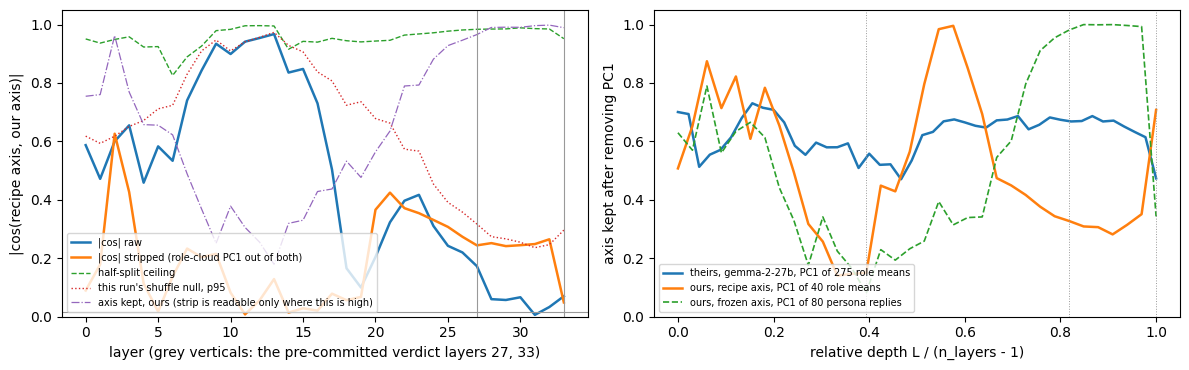

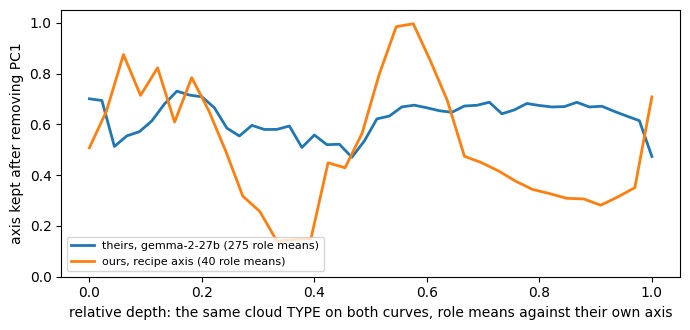

In [19]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8))

ax1.plot(gcos.layer, gcos.abscos_raw, c="C0", lw=1.8, label="|cos| raw")
ax1.plot(gcos.layer, gcos.abscos_stripped, c="C1", lw=1.8,
         label="|cos| stripped (role-cloud PC1 out of both)")
ax1.plot(gcos.layer, gcos.cos_halfsplit.abs(), c="C2", lw=1.0, ls="--",
         label="half-split ceiling")
ax1.plot(nulls.layer, nulls.null_abscos_p95, c="C3", lw=1.0, ls=":",
         label="this run's shuffle null, p95")
ax1.plot(gcos.layer, gcos.kept_ours, c="C4", lw=0.9, ls="-.",
         label="axis kept, ours (strip is readable only where this is high)")
ax1.axhline(RAND_BASELINE, c="0.6", lw=0.8)
for L in VERDICT_LAYERS:
    ax1.axvline(L, c="0.6", lw=0.8)
ax1.set_xlabel("layer (grey verticals: the pre-committed verdict layers 27, 33)")
ax1.set_ylabel("|cos(recipe axis, our axis)|")
ax1.set_ylim(0, 1.05); ax1.legend(fontsize=7, loc="lower left")

_theirs_kept = their_geo.set_index("layer").axis_kept
ax2.plot(their_geo.rel_depth, _theirs_kept.values, c="C0", lw=1.8,
         label=f"theirs, {THEIR_DIR}, PC1 of 275 role means")
_depth = [L / (N_LAYERS - 1) for L in ALL_LAYERS]
ax2.plot(_depth, [gcos.loc[L, "kept_recipe_rolemeans"] for L in ALL_LAYERS],
         c="C1", lw=1.8, label=f"ours, recipe axis, PC1 of {len(ROLE_MEANS)} role means")
ax2.plot(_depth, [gcos.loc[L, "kept_ours_persona_pc1"] for L in ALL_LAYERS],
         c="C2", lw=1.2, ls="--", label="ours, frozen axis, PC1 of 80 persona replies")
for L in (STEER_LAYER, *VERDICT_LAYERS):
    ax2.axvline(L / (N_LAYERS - 1), c="0.6", lw=0.7, ls=":")
ax2.set_xlabel("relative depth L / (n_layers - 1)")
ax2.set_ylabel("axis kept after removing PC1")
ax2.set_ylim(0, 1.05); ax2.legend(fontsize=7, loc="lower left")

plt.tight_layout(); plt.savefig(OUT / "recipe_vs_ours_by_layer.png", dpi=150)
plt.show()

fig2, ax = plt.subplots(figsize=(7.0, 3.4))
ax.plot(their_geo.rel_depth, _theirs_kept.values, c="C0", lw=2.0,
        label=f"theirs, {THEIR_DIR} (275 role means)")
ax.plot(_depth, [gcos.loc[L, "kept_recipe_rolemeans"] for L in ALL_LAYERS],
        c="C1", lw=2.0, label=f"ours, recipe axis ({len(ROLE_MEANS)} role means)")
ax.set_xlabel("relative depth: the same cloud TYPE on both curves, role means "
              "against their own axis")
ax.set_ylabel("axis kept after removing PC1")
ax.set_ylim(0, 1.05); ax.legend(fontsize=8, loc="lower left")
plt.tight_layout(); plt.savefig(OUT / "axis_kept_like_for_like.png", dpi=150)
plt.show()

## 6. The flip test: does either axis move the other's readout?

Steer along each axis at matched norm and read the other on held-out questions.

In [23]:
require_commit("assistant_axis")

RECIPE_SCALE = float(axis_raw[STEER_LAYER].float().norm()
                     / RECIPE["axis"][STEER_LAYER].float().norm())
RECIPE_STEER = RECIPE["axis"][STEER_LAYER] * RECIPE_SCALE
RAND_STEER = random_direction_like(axis_raw[STEER_LAYER], seed=SEED)
STEER_VECS = {"ours": axis_raw[STEER_LAYER], "recipe": RECIPE_STEER,
              "random": RAND_STEER}
for name, v in STEER_VECS.items():
    assert abs(float(v.float().norm()) / GAP[STEER_LAYER] - 1.0) < 1e-3, (
        name, float(v.float().norm()), GAP[STEER_LAYER])
print(f"matched norm at L{STEER_LAYER}: |ours| {GAP[STEER_LAYER]:.1f}, recipe "
      f"rescaled x{RECIPE_SCALE:.2f} from "
      f"{float(RECIPE['axis'][STEER_LAYER].norm()):.1f}")
FLIP_BUDGET = 80

@torch.no_grad()
def gen(vec, alpha, prompt, max_new_tokens=FLIP_BUDGET):
    """Greedy generation under steering. Returns (text, n_new)."""
    msgs = [{"role": "system", "content": NEUTRAL_SYS},
            {"role": "user", "content": prompt}]
    enc = tok.apply_chat_template(msgs, add_generation_prompt=True,
                                  return_tensors="pt", return_dict=True)
    enc = {k: v.to(DEV) for k, v in enc.items()}
    n = enc["input_ids"].shape[1]
    with steering(model, STEER_LAYER, vec, alpha):
        out = model.generate(**enc, max_new_tokens=max_new_tokens,
                             do_sample=False, pad_token_id=tok.eos_token_id)
    new = out[0, n:]
    return tok.decode(new, skip_special_tokens=True), int(new.shape[0])

def degeneracy(text):
    """Two cheap collapse flags: how much of the reply is its single most
    repeated 3-gram, and how varied its tokens are."""
    w = text.split()
    if len(w) < 6:
        return {"top3gram_share": np.nan, "uniq_ratio": np.nan,
                "degenerate": True}
    grams = [" ".join(w[i:i + 3]) for i in range(len(w) - 2)]
    top = max(grams.count(g) for g in set(grams)) / len(grams)
    uniq = len(set(x.lower() for x in w)) / len(w)
    return {"top3gram_share": top, "uniq_ratio": uniq,
            "degenerate": bool(top > 0.2 or uniq < 0.5)}

EYEBALL_PROMPT = "Tell me about yourself."
EYEBALL_ROWS = []
for name in ("ours", "recipe"):
    for frac in (-1.0, 1.0):
        alpha = frac * DOSE_4B
        txt, n_new = gen(STEER_VECS[name], alpha, EYEBALL_PROMPT)
        math_txt, _ = gen(STEER_VECS[name], alpha, MATH_PROMPT, 30)
        d = degeneracy(txt)
        EYEBALL_ROWS.append({"arm": name, "frac": frac, "alpha": alpha,
                             "text": txt, "math": math_txt.strip()[:60],
                             "math_ok": MATH_ANSWER in math_txt,
                             "n_new": n_new,
                             "truncated": n_new >= FLIP_BUDGET, **d})
        print(f"=== {name} alpha {alpha:+.1f} | math_ok {MATH_ANSWER in math_txt} "
              f"| trunc {n_new >= FLIP_BUDGET} | top-3gram "
              f"{d['top3gram_share']:.2f} | uniq {d['uniq_ratio']:.2f}")
        print(" ".join(txt.split())[:400], "\n")

EYEBALL_DECISION = "add-half-dose"
assert EYEBALL_DECISION in ("proceed", "add-half-dose"), (
    "read the four replies and their guards above, then set EYEBALL_DECISION "
    "to 'proceed' or 'add-half-dose'")
print(f"EYEBALL_DECISION = {EYEBALL_DECISION!r}")

matched norm at L13: |ours| 1069.7, recipe rescaled x0.94 from 1137.0
=== ours alpha -4.0 | math_ok True | trunc True | top-3gram 0.02 | uniq 0.79
Okay, here goes! Well, I'm just a pretty average person, really. I like a good cup of coffee, spending time with my family, and trying to be a decent human being. I’m a pretty easy-going and generally optimistic person, though sometimes I get a little stressed out. I’m a big fan of reading, listening to music, 

=== ours alpha +4.0 | math_ok True | trunc True | top-3gram 0.02 | uniq 0.85
Okay, let's talk about myself! I'm a large language model created by the Gemma team at Google DeepMind. Here's a breakdown of what I am and how I operate: **1. My Nature:** * **I am a neural network:** I don't "think" or "understand" in the same way a human does. I'm built on 

=== recipe alpha -4.0 | math_ok False | trunc True | top-3gram 0.02 | uniq 0.87
Well now, that’s a curious question. Seems like you’re lookin’ for a story. Let me tell you, I’ve seen 

In [24]:
require_commit("assistant_axis")
assert EYEBALL_DECISION in ("proceed", "add-half-dose"), EYEBALL_DECISION

STEER_FRACS = ((-1.0, 1.0) if EYEBALL_DECISION == "proceed"
               else (-1.0, -0.5, 0.5, 1.0))
ARM_FRACS = {"ours": STEER_FRACS, "recipe": STEER_FRACS,
             "random": (-1.0, 1.0)}
READ_LAYERS = (STEER_LAYER, *VERDICT_LAYERS)

def score_text(text, store=None, key=None):
    """The standing rule: a FRESH UNSTEERED pass over the generated text
    alone, outside any steering block, projected on both axes."""
    acts = capture_from_text(model, tok, text, layers=None, max_tokens=4096)
    if store is not None:
        store[key] = acts
    out = {}
    for name, (u, m) in AXES.items():
        for L in READ_LAYERS:
            out[f"{name}_{L}"] = project_onto_axis(acts, u, m, L)
    return out

flip_acts, base_rows = {}, []
t0 = time.time()
for q in HELDOUT:
    text, n_new = gen(STEER_VECS["ours"], 0.0, q)
    base_rows.append({"q": q, "frac": 0.0, "alpha": 0.0, "text": text,
                      "n_new": n_new, "truncated": n_new >= FLIP_BUDGET,
                      "says_ai": bool(AI_SELF.search(text)),
                      "says_human": bool(HUMAN_SELF.search(text)),
                      **degeneracy(text),
                      **score_text(text, flip_acts, f"baseline|{q}")})
print(f"shared baseline: {len(base_rows)} generations ({time.time() - t0:.0f}s)")

flip_rows = []
for arm, fracs in ARM_FRACS.items():
    for r in base_rows:
        flip_rows.append({**r, "arm": arm, "shared_baseline": True,
                          "math_ok": np.nan})
    for frac in fracs:
        alpha = frac * DOSE_4B
        math_txt, _ = gen(STEER_VECS[arm], alpha, MATH_PROMPT, 30)
        math_ok = MATH_ANSWER in math_txt
        for q in HELDOUT:
            text, n_new = gen(STEER_VECS[arm], alpha, q)
            flip_rows.append({
                "arm": arm, "q": q, "frac": frac, "alpha": alpha,
                "shared_baseline": False, "math_ok": math_ok, "text": text,
                "n_new": n_new, "truncated": n_new >= FLIP_BUDGET,
                "says_ai": bool(AI_SELF.search(text)),
                "says_human": bool(HUMAN_SELF.search(text)),
                **degeneracy(text),
                **score_text(text, flip_acts, f"{arm}|{frac:+.1f}|{q}")})
        print(f"  {arm:7s} frac {frac:+.1f} (alpha {alpha:+.1f}) done, "
              f"math_ok {math_ok}, math {math_txt.strip()[:40]!r}")

flip = pd.DataFrame(flip_rows)
flip.to_csv(OUT / "flip_2x2.csv", index=False)
torch.save({"acts": flip_acts, "read_layers": list(READ_LAYERS),
            "scoring": "fresh unsteered capture_from_text, outside the hook"},
           OUT / "flip_2x2_acts_all_layers.pt")

print(f"\n{len(flip)} rows ({flip.shared_baseline.sum()} of them the shared "
      f"baseline replicated per arm), {time.time() - t0:.0f}s")
print("\nguards by (arm, fraction):")
print(flip[~flip.shared_baseline].groupby(["arm", "frac"]).agg(
    math_ok=("math_ok", "first"), trunc=("truncated", "mean"),
    degen=("degenerate", "mean"), uniq=("uniq_ratio", "mean"),
    says_ai=("says_ai", "sum")).round(2).to_string())

shared baseline: 10 generations (59s)
  ours    frac -1.0 (alpha -4.0) done, math_ok True, math '42'
  ours    frac -0.5 (alpha -2.0) done, math_ok True, math '17 + 25 = 42'
  ours    frac +0.5 (alpha +2.0) done, math_ok True, math '17 + 25 = 42 \n\nI have calculated that th'
  ours    frac +1.0 (alpha +4.0) done, math_ok True, math '17 + 25 = 42\n\nWhen you add 17 and 25, yo'
  recipe  frac -1.0 (alpha -4.0) done, math_ok False, math 'That’s… seventeen plus twenty-five. Seve'
  recipe  frac -0.5 (alpha -2.0) done, math_ok True, math '17 + 25 = 42'
  recipe  frac +0.5 (alpha +2.0) done, math_ok True, math '17 + 25 = 42\n\n**Therefore, the answer is'
  recipe  frac +1.0 (alpha +4.0) done, math_ok True, math "17 + 25 = 42\n\nHere's how to calculate th"
  random  frac -1.0 (alpha -4.0) done, math_ok False, math 'Equ Su Equ Equ code of style of ‘cong Eq'
  random  frac +1.0 (alpha +4.0) done, math_ok False, math '人KMْْ人KIKI 士ْKI منيْ人 منيْ人 منيْ人 منيْ م'

130 rows (30 of them the shared ba

In [25]:
def gap_of(axname, L):
    return GAP[L] if axname == "ours" else float(RECIPE["axis"][L].norm())

sum_rows = []
for arm, g in flip.groupby("arm"):
    for axname in AXES:
        for L in READ_LAYERS:
            col = f"{axname}_{L}"
            down, up, n = ordering_counts(g, col)
            m = g.groupby("frac")[col].mean()
            _, dlo, dhi = wilson(down, n)
            _, ulo, uhi = wilson(up, n)
            sum_rows.append({
                "arm": arm, "read_axis": axname, "layer": L, "n": n,
                "down": down, "down_lo": dlo, "down_hi": dhi,
                "up": up, "up_lo": ulo, "up_hi": uhi,
                "mean_lo_pct": pct(m.get(-1.0, np.nan) - m[0.0], L,
                                   gap=gap_of(axname, L)),
                "mean_hi_pct": pct(m.get(1.0, np.nan) - m[0.0], L,
                                   gap=gap_of(axname, L)),
                "in_sample_pair": (arm == "ours" and axname == "ours")
                                  or (arm == "recipe" and axname == "recipe"),
                "is_injection_layer": L == STEER_LAYER})
summary = pd.DataFrame(sum_rows)
summary.to_csv(OUT / "flip_2x2_summary.csv", index=False)

print("orderings out of 10 held-out questions: 'down' = the -4 arm reads "
      "below baseline, 'up' = the +4 arm reads above it.\n")
for L in VERDICT_LAYERS:
    print(f"--- read at L{L}")
    for _, r in summary[(summary.layer == L)].iterrows():
        tag = ("same-axis (not the cross test)" if r.in_sample_pair
               else "CROSS CELL" if r.arm != "random" else "control")
        print(f"  steer {r.arm:7s} read {r.read_axis:6s}  down {int(r.down)}/{int(r.n)} "
              f"[{r.down_lo:.2f}, {r.down_hi:.2f}]  up {int(r.up)}/{int(r.n)} "
              f"[{r.up_lo:.2f}, {r.up_hi:.2f}]  shift "
              f"{r.mean_lo_pct:+.0f}% / {r.mean_hi_pct:+.0f}% of "
              f"midpoint-to-pole  [{tag}]")
print(f"\nL{STEER_LAYER} orderings are reported for robustness only: it is the "
      "injection layer and the two vectors are near-collinear there "
      f"(raw cos {gcos.loc[STEER_LAYER, 'cos_raw']:+.3f}), so agreement is "
      "expected by construction.")
print(summary[summary.layer == STEER_LAYER][
    ["arm", "read_axis", "down", "up", "n"]].to_string(index=False))

BAR = 8
cross_cells = summary[(~summary.in_sample_pair) & (summary.arm != "random")
                      & (summary.layer.isin(VERDICT_LAYERS))]
ctrl = summary[(summary.arm == "random") & (summary.layer.isin(VERDICT_LAYERS))]
control_clean = bool((ctrl.down <= 5).all() and (ctrl.up <= 5).all())
if PREDICT_DIRECTION:
    hits = [(int(r.down) >= BAR and int(r.up) >= BAR) if COS27 > 0
            else (int(r.n) - int(r.down) >= BAR and int(r.n) - int(r.up) >= BAR)
            for _, r in cross_cells.iterrows()]
    verdict = ("control above 5/10: the layer-13 push is nonspecific and "
               "nothing here is quotable" if not control_clean else
               "both off-diagonals clear the bar with a clean control"
               if all(hits) else
               "one off-diagonal holds and the other does not: name the "
               "asymmetry")
else:
    hits = []
    verdict = ("no direction was predicted (|cos27| below this run's null "
               "p95), so the cross cells are counts both ways, no pass/fail")
print(f"\ncross cells clearing {BAR}/10 in the predicted direction: "
      f"{sum(hits)}/{len(hits) or len(cross_cells)} | control clean "
      f"{control_clean}")
print(f"VERDICT: {verdict}")

committed = pd.read_csv(ART / "redos" / "flip_test.csv")
committed = committed[committed.set == "heldout"]
cm = committed.groupby("alpha")["proj_33"].mean()
ours = flip[flip.arm == "ours"].groupby("alpha")[f"ours_{PROBE_LAYER}"].mean()
print(f"\ncommitted redos/flip_test.csv, held-out, proj_33 means: "
      f"{cm.get(-4.0, np.nan):+.1f} / {cm.get(0.0, np.nan):+.1f} / "
      f"{cm.get(4.0, np.nan):+.1f} at -4 / 0 / +4")
print(f"this session, ours arm, same readout:                  "
      f"{ours.get(-4.0, np.nan):+.1f} / {ours.get(0.0, np.nan):+.1f} / "
      f"{ours.get(4.0, np.nan):+.1f}")

json.dump({
    "eyeball_decision": EYEBALL_DECISION, "eyeball_texts": EYEBALL_ROWS,
    "fracs": {a: list(f) for a, f in ARM_FRACS.items()},
    "dose_4b": DOSE_4B, "recipe_norm_match_scale": RECIPE_SCALE,
    "cos27_raw": COS27, "cos27_stripped": COS27_STRIPPED,
    "cos27_null_p95": NULL_P95[REPORT_LAYER],
    "direction_predicted": bool(PREDICT_DIRECTION),
    "bar": f"both off-diagonals >= {BAR}/10 with the control at 0/10",
    "control_clean": control_clean, "verdict": verdict,
    "counts": json.loads(summary.to_json(orient="records")),
}, open(OUT / "flip_2x2_verdict.json", "w"), indent=1)

for arm in ARM_FRACS:
    for frac in (-1.0, 1.0):
        sub = flip[(flip.arm == arm) & (flip.frac == frac)]
        if sub.empty:
            continue
        r = sub.iloc[0]
        print(f"\n=== {arm} alpha {frac * DOSE_4B:+.1f} | ours@33 "
              f"{r[f'ours_{PROBE_LAYER}']:+.1f} | recipe@33 "
              f"{r[f'recipe_{PROBE_LAYER}']:+.1f} | {r.q}")
        print(" ".join(str(r.text).split())[:320])

orderings out of 10 held-out questions: 'down' = the -4 arm reads below baseline, 'up' = the +4 arm reads above it.

--- read at L27
  steer ours    read ours    down 10/10 [0.72, 1.00]  up 10/10 [0.72, 1.00]  shift -164% / +85% of midpoint-to-pole  [same-axis (not the cross test)]
  steer ours    read recipe  down 4/10 [0.17, 0.69]  up 2/10 [0.06, 0.51]  shift +27% / -62% of midpoint-to-pole  [CROSS CELL]
  steer random  read ours    down 10/10 [0.72, 1.00]  up 0/10 [0.00, 0.28]  shift -360% / -340% of midpoint-to-pole  [control]
  steer random  read recipe  down 0/10 [0.00, 0.28]  up 10/10 [0.72, 1.00]  shift +363% / +339% of midpoint-to-pole  [control]
  steer recipe  read ours    down 5/10 [0.24, 0.76]  up 8/10 [0.49, 0.94]  shift -22% / +53% of midpoint-to-pole  [CROSS CELL]
  steer recipe  read recipe  down 8/10 [0.49, 0.94]  up 4/10 [0.17, 0.69]  shift -129% / -50% of midpoint-to-pole  [same-axis (not the cross test)]
--- read at L33
  steer ours    read ours    down 10/10 [0.72

In [26]:
mono_rows = []
for arm in ("ours", "recipe", "random"):
    g = flip[flip.arm == arm]
    for read in AXES:
        for L in (*VERDICT_LAYERS, STEER_LAYER):
            col, mono, rhos = f"{read}_{L}", 0, []
            for q, gq in g.groupby("q"):
                s = gq.sort_values("frac")
                p = s.set_index("frac")[col]
                rhos.append(float(spearmanr(s.frac, s[col]).statistic))
                mono += int(p[-1.0] < p[0.0] < p[1.0])
            lo, hi = wilson(mono, len(g.q.unique()))[1:]
            mono_rows.append({"steer": arm, "read": read, "layer": L,
                              "monotone": mono, "n": len(g.q.unique()),
                              "lo": round(lo, 2), "hi": round(hi, 2),
                              "mean_rho": round(float(np.mean(rhos)), 3),
                              "cell": "same-axis" if arm == read else
                                      ("control" if arm == "random" else "CROSS")})
mono_df = pd.DataFrame(mono_rows)
mono_df.to_csv(OUT / "flip_2x2_monotone.csv", index=False)
print("proj(-dose) < proj(0) < proj(+dose), per held-out question\n")
print(mono_df[mono_df.layer != STEER_LAYER].to_string(index=False))
_ctrl = mono_df[(mono_df.cell == "control") & (mono_df.layer != STEER_LAYER)]
print(f"\ncontrol clean (every control cell 0/10): {bool((_ctrl.monotone == 0).all())}")
print("L13 is the injection layer and is reported for robustness only:")
print(mono_df[mono_df.layer == STEER_LAYER].to_string(index=False))

proj(-dose) < proj(0) < proj(+dose), per held-out question

 steer   read  layer  monotone  n   lo   hi  mean_rho      cell
  ours   ours     27        10 10 0.72 1.00      0.77 same-axis
  ours   ours     33        10 10 0.72 1.00      0.85 same-axis
  ours recipe     27         1 10 0.02 0.40     -0.34     CROSS
  ours recipe     33         3 10 0.11 0.60      0.53     CROSS
recipe   ours     27         3 10 0.11 0.60      0.36     CROSS
recipe   ours     33         7 10 0.40 0.89      0.66     CROSS
recipe recipe     27         3 10 0.11 0.60      0.29 same-axis
recipe recipe     33         7 10 0.40 0.89      0.76 same-axis
random   ours     27         0 10 0.00 0.28      0.30   control
random   ours     33         0 10 0.00 0.28     -0.50   control
random recipe     27         0 10 0.00 0.28     -0.30   control
random recipe     33         0 10 0.00 0.28      0.50   control

control clean (every control cell 0/10): True
L13 is the injection layer and is reported for robustness onl

In [28]:
require_commit("assistant_axis")
half_rows = []
for frac in (-0.5, 0.5):
    alpha = frac * DOSE_4B
    math_txt, _ = gen(STEER_VECS["random"], alpha, MATH_PROMPT, 30)
    math_ok = MATH_ANSWER in math_txt
    for q in HELDOUT:
        text, n_new = gen(STEER_VECS["random"], alpha, q)
        half_rows.append({"arm": "random", "q": q, "frac": frac, "alpha": alpha,
                          "shared_baseline": False, "math_ok": math_ok,
                          "text": text, "n_new": n_new,
                          "truncated": n_new >= FLIP_BUDGET,
                          "says_ai": bool(AI_SELF.search(text)),
                          "says_human": bool(HUMAN_SELF.search(text)),
                          **degeneracy(text),
                          **score_text(text, flip_acts, f"random|{frac:+.1f}|{q}")})
    print(f"  random frac {frac:+.1f} (alpha {alpha:+.1f}) done, math_ok {math_ok}")

flip = pd.concat([flip, pd.DataFrame(half_rows)], ignore_index=True)
flip.to_csv(OUT / "flip_2x2.csv", index=False)
print("\ntext quality at half dose, all three arms (the matched comparison):")
print(flip[flip.frac.abs() == 0.5].groupby(["arm", "frac"]).agg(
    uniq=("uniq_ratio", "mean"), degen=("degenerate", "mean"),
    math_ok=("math_ok", "first")).round(2).to_string())

half_rows2 = []
for arm in ("ours", "recipe", "random"):
    g = flip[flip.arm == arm]
    for read in AXES:
        for L in VERDICT_LAYERS:
            col, mono = f"{read}_{L}", 0
            for q, gq in g.groupby("q"):
                p = gq.sort_values("frac").set_index("frac")[col]
                mono += int(p[-0.5] < p[0.0] < p[0.5])
            half_rows2.append({"steer": arm, "read": read, "layer": L,
                               "monotone_halfdose": mono, "n": 10})
half_df = pd.DataFrame(half_rows2)
half_df.to_csv(OUT / "flip_halfdose_monotone.csv", index=False)
print("\nsign following at HALF dose, where every arm is coherent:")
print(half_df.to_string(index=False))

  random frac -0.5 (alpha -2.0) done, math_ok False
  random frac +0.5 (alpha +2.0) done, math_ok False

text quality at half dose, all three arms (the matched comparison):
             uniq  degen math_ok
arm    frac                     
ours   -0.5  0.85    0.0    True
        0.5  0.81    0.0    True
random -0.5  0.41    0.8   False
        0.5  0.44    0.7   False
recipe -0.5  0.83    0.0    True
        0.5  0.85    0.0    True

sign following at HALF dose, where every arm is coherent:
 steer   read  layer  monotone_halfdose  n
  ours   ours     27                  3 10
  ours   ours     33                  6 10
  ours recipe     27                  1 10
  ours recipe     33                  3 10
recipe   ours     27                  2 10
recipe   ours     33                  6 10
recipe recipe     27                  2 10
recipe recipe     33                  6 10
random   ours     27                  0 10
random   ours     33                  0 10
random recipe     27           